# Model Evaluation

# Data Preprocessing

In [1]:
# Import tools
import pandas as pd
from pathlib import Path


Import pandas and Path for model evaluation.

In [2]:
# Load split data with engineered features

train_fe = pd.read_csv("data/processed/train_fe.csv")
validation_fe = pd.read_csv("data/processed/val_fe.csv")
test_fe = pd.read_csv("data/processed/test_fe.csv")

train_fe.head()


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,diag_1_group,diag_2_group,diag_3_group,readmit_30,age_numeric,prior_utilization,prior_inpatient,num_diabetes_meds,insulin_used,diabetes_diag_count
0,Caucasian,Female,[60-70),1,1,7,4,Unknown,Unknown,42,...,"Symptoms, Signs, and Ill-Defined Conditions",Diabetes,Diabetes,0,65,0,0,1,1,2
1,Caucasian,Female,[70-80),2,6,4,3,Unknown,Unknown,25,...,Circulatory,Circulatory,Circulatory,0,75,0,0,0,0,0
2,Caucasian,Male,[80-90),3,1,1,1,MC,Cardiology,40,...,Circulatory,Circulatory,Diabetes,0,85,1,0,0,0,1
3,Caucasian,Male,[70-80),6,3,4,3,Unknown,Unknown,47,...,Circulatory,Circulatory,Circulatory,0,75,0,0,1,1,0
4,Caucasian,Female,[60-70),2,1,1,3,Unknown,InternalMedicine,64,...,Digestive,"Endocrine, Nutritional, Metabolic, and Blood",Supplementary Factors,0,65,0,0,1,0,0


Load the engineered splits. I will use training data to fit the models and validation data to compare them. Test data is reserved for the final results.

In [3]:
# Separate feature and columns

X_train = train_fe.drop(columns=["readmit_30", "age"]) # age column was dropped -- will use the age_numeric feature instead
y_train = train_fe["readmit_30"]

X_val = validation_fe.drop(columns=["readmit_30", "age"])
y_val = validation_fe["readmit_30"]

X_test = test_fe.drop(columns=["readmit_30", "age"])
y_test = test_fe["readmit_30"]

X_train.head()


,race,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,...,diabetesMed,diag_1_group,diag_2_group,diag_3_group,age_numeric,prior_utilization,prior_inpatient,num_diabetes_meds,insulin_used,diabetes_diag_count
0,Caucasian,Female,1,1,7,4,Unknown,Unknown,42,3,...,Yes,"Symptoms, Signs, and Ill-Defined Conditions",Diabetes,Diabetes,65,0,0,1,1,2
1,Caucasian,Female,2,6,4,3,Unknown,Unknown,25,3,...,No,Circulatory,Circulatory,Circulatory,75,0,0,0,0,0
2,Caucasian,Male,3,1,1,1,MC,Cardiology,40,6,...,No,Circulatory,Circulatory,Diabetes,85,1,0,0,0,1
3,Caucasian,Male,6,3,4,3,Unknown,Unknown,47,1,...,Yes,Circulatory,Circulatory,Circulatory,75,0,0,1,1,0
4,Caucasian,Female,2,1,1,3,Unknown,InternalMedicine,64,3,...,Yes,Digestive,"Endocrine, Nutritional, Metabolic, and Blood",Supplementary Factors,65,0,0,1,0,0


Separate readmit_30 from the features. Drop age and use age_numeric instead. The original outcome should not be included as a predictor.

In [4]:
# Identify categorical columns

categorical_cols = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

categorical_cols += [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]

# Remove any repeated column names
categorical_cols = list(dict.fromkeys(categorical_cols))

print("Categorical columns:")
print(categorical_cols)


Categorical columns:
['race', 'gender', 'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'change', 'diabetesMed', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']


Identify categorical columns. Include admission_type_id, discharge_disposition_id, and admission_source_id since they represent categories.

In [5]:
# Identify numerical columns

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Numeric columns:")
print(numeric_cols)


Numeric columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_numeric', 'prior_utilization', 'prior_inpatient', 'num_diabetes_meds', 'insulin_used', 'diabetes_diag_count']


Identify the numerical columns. All remaining predictors that are not categorical will use numerical preprocessing.

In [6]:
# Import processing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


Import preprocessing tools. Use a pipeline so the preprocessing is fitted together with the model.

In [7]:
# Define numeric preprocessing
# Median was used to fill the missing values since the numeric features is skewed and has some unusually large values
# Median is much less affected than the mean by extreme values

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # fills missing nuumerical values with training median
    ("scaler", StandardScaler()),
])


Fill missing numerical values using the training median. StandardScaler uses the training mean and standard deviation.

In [8]:
# Define Categorical Preprocessing
# for remaining categories like payer_code, missing values are filled with "Unknown"

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Unknown",
        ),
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore"), # so the model can process categories it did not see during training
    ),
])


Fill missing categorical values with Unknown and apply one-hot encoding. Ignore new categories when predicting validation or test patients.

In [9]:
# Combine both numeric and categorical preprocessing

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
])

print("Preprocessing pipeline is ready.")


Preprocessing pipeline is ready.


Combine numerical and categorical preprocessing. The preprocessor is defined here and will be fitted using training data.

# Dummy baseline vs Logistic Regression Model

#### The dummy baseline tells us how well a model performs without learning relationships between patient features and readmission. It gives us a starting point that the trained models should beat.

| Metric | Interpretation |
|---|---|
| Average precision: **0.1603** | Better than the dummy’s **0.0897**—the model ranks readmitted patients more effectively. |
| ROC-AUC: **0.6378** | Some ability to distinguish readmitted from non-readmitted patients, but performance is modest. |
| Precision: **0.2857** | About **28.57%** of flagged patients were actually readmitted. |
| Recall: **0.0021** | Only about **0.21%** of readmitted patients were flagged. |
| F1: **0.0042** | Very low because recall is extremely low. |


In [10]:
# Import modeling tools

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)

import matplotlib.pyplot as plt


Import the dummy baseline, logistic regression, and evaluation metrics. Use AP and ROC-AUC for ranking, then precision and recall at the selected threshold.

In [11]:
# Train dummy baseline
# This model assigns everyone the training positive rate (8.975) as their predicted probability

dummy_model = DummyClassifier(strategy="prior")

dummy_model.fit(X_train, y_train)


,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


The dummy baseline assigns the training positive rate to everyone. Validation AP is about 0.0897 and ROC-AUC is 0.50.

In [12]:
# Logistic regression pipeline
# fits preprocessing using training data and then trains the model

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
        ),
    ),
])

logistic_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

Train logistic regression using the preprocessing pipeline. The default threshold is 0.50, which may miss many positives because readmission is uncommon.

In [13]:
# Predict on validation data

dummy_probability = dummy_model.predict_proba(X_val)[:, 1]
dummy_prediction = dummy_model.predict(X_val)

logistic_probability = logistic_model.predict_proba(X_val)[:, 1]
logistic_prediction = logistic_model.predict(X_val)


Predict the validation probabilities and classes. Use these results to compare the baseline and logistic regression.

In [14]:
# Compare validation performance
# use average precision (AP) to compare performance


results = []

for name, probability, prediction in [
    ("Dummy baseline", dummy_probability, dummy_prediction),
    ("Logistic regression", logistic_probability, logistic_prediction),
]:
    results.append({
        "Model": name,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(y_val, probability),
        "Precision": precision_score(
            y_val, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_val, prediction, zero_division=0
        ),
        "F1": f1_score(
            y_val, prediction, zero_division=0
        ),
    })

comparison = pd.DataFrame(results).set_index("Model")

comparison.round(4)

# Logistic regression average precision of 16% beats the dummy baseline average of 8.97% (positive rate)
# Suggest that logistic regression learned useful predictive information
# Precision still low at 28.57%, modest ROC-AUC at 0.64, with very low recall


,Average precision,ROC-AUC,Precision,Recall,F1
Model,,,,,
Dummy baseline,0.0897,0.5000,0.0000,0.0000,0.0000
Logistic regression,0.1603,0.6378,0.2857,0.0021,0.0042


Logistic regression AP = 0.1603 and ROC-AUC = 0.6378, better than the dummy baseline. Recall at threshold 0.50 is only 0.21%, so the model flags very few readmissions.

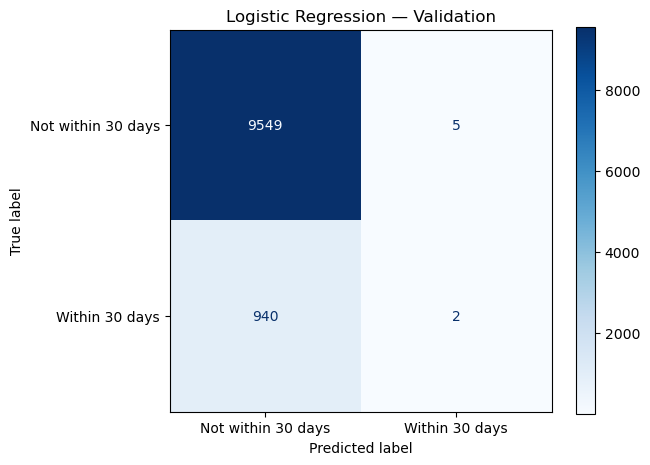

In [15]:
# logistic regression confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_val,
    logistic_prediction,
    display_labels=["Not within 30 days", "Within 30 days"],
    cmap="Blues",
    values_format="d",
)

plt.title("Logistic Regression — Validation")
plt.tight_layout()
plt.show()


Plot the validation confusion matrix. Need to consider missed readmissions and false alerts, not only the large number of correct negative predictions.

In [16]:
# Save baseline validation metrics

Path("reports").mkdir(parents=True, exist_ok=True)

comparison.to_csv("reports/baseline_validation_metrics.csv")

print("Saved baseline validation metrics.")


Saved baseline validation metrics.


Save the baseline validation metrics for reference.

In [17]:
# Metric comparison for different thresholds
# Threshold is the cutoff used to turn a models predicted risk to yes (readmitted within 30 days) or no (not readmitted)
# Example: If the threshold is set at 0.10, Score => 0.10 (flag the patient), =< 0.10 *(do not flag the patient)
# In general, lowering the threshold will flag more patients (increase in recall) but create more false alerts (lower precision)
# Choose threshold that have the right balance between precision and recall 

threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:

    prediction = (
        logistic_probability >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Patients flagged": prediction.sum(),
        "Flagged (%)": prediction.mean() * 100,
        "Precision": precision_score(
            y_val, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_val, prediction, zero_division=0
        ),
        "F1": f1_score(
            y_val, prediction, zero_division=0
        ),
    })

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison.round(4)


,Threshold,Patients flagged,Flagged (%),Precision,Recall,F1
0,0.05,8647,82.3838,0.0995,0.9130,0.1794
1,0.10,2915,27.7725,0.1427,0.4416,0.2157
2,0.15,1054,10.0419,0.2021,0.2261,0.2134
3,0.20,467,4.4493,0.2655,0.1316,0.1760
4,0.30,117,1.1147,0.2821,0.0350,0.0623
5,0.50,7,0.0667,0.2857,0.0021,0.0042


Threshold 0.10 has the highest F1 among the six values tested. It flags 27.63% of patients and captures 44.48% of readmissions, with precision of 14.45%. Lower thresholds increase follow-up workload.

| Outcome | Meaning | Goal | Metric to prioritize |
|---|---|---|---|
| **False positive (FP)** | Flagged, but not readmitted | Minimize false alerts | **Precision** for reliable alerts; **specificity** for fewer false alerts among non-readmitted patients |
| **False negative (FN)** | Not flagged, but readmitted | Minimize missed readmissions | **Recall / sensitivity** |
| **True positive (TP)** | Flagged and actually readmitted | Catch more actual readmissions | **Recall / sensitivity** |
| **True negative (TN)** | Not flagged and not readmitted | Correctly clear more non-readmitted patients | **Specificity** |


Logistic regression threshold comparison

- 0.10: Highest F1 among the thresholds tested. Flags 27.63% of patients and catches 44.48% of readmissions.
- 0.15: Flags approximately 10% of patients and catches 22.82% of readmissions. This could suit a hypothetical team with capacity to follow up about one in ten patients.



Lowering the logistic regression threshold from 0.50 to 0.10 increased validation recall from 0.21% to 44.48%, while precision decreased from 28.57% to 14.45%. The proportion of patients flagged increased from 0.07% to 27.63%. Threshold 0.10 produced the highest F1 among the six thresholds evaluated, but final selection requires consideration of follow-up capacity and comparison with other models.

In [18]:
# Save threshold comparison

threshold_comparison.to_csv(
    "reports/logistic_threshold_validation.csv",
    index=False,
)


Save the logistic threshold comparison. The final threshold should consider validation performance and available follow-up capacity.

# Dimensionality Reduction

### Feature Selection

In [19]:
# Import tools

from sklearn.base import clone
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score


Import feature selection tools. Use clone to create a new unfitted pipeline for each experiment.

In [20]:
# Define feature selector

selector = SelectFromModel(
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.1, # starting setting. smaller values generally produce stronger selection
        max_iter=2000,
        random_state=42,
    ),
    threshold=0.00001,
)


Use L1 logistic regression to select features. C=0.1 applies regularization, while the coefficient threshold determines which features remain.

In [21]:
# Selected feature pipeline
# final logistic regression uses the same setting as the baseline. Only feature selection is added
selected_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selector", selector),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
        ),
    ),
])


Combine preprocessing, feature selection, and logistic regression in one pipeline. Fit the selection using training data only.

In [22]:
# Fit using training data only

selected_model.fit(X_train, y_train)


/opt/anaconda3/envs/AIM/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/AIM/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diffe

Train the selected-feature model. Use validation data afterward to check the effect of feature selection.

In [23]:
# Check how many features were retained

feature_names = (
    selected_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

selected_mask = (
    selected_model.named_steps["selector"]
    .get_support()
)

print("Encoded features before selection:", len(feature_names))
print("Encoded features retained:", selected_mask.sum())
print("Encoded features removed:", (~selected_mask).sum())


Encoded features before selection: 282
Encoded features retained: 83
Encoded features removed: 199


Feature selection retained 82 out of 283 encoded features. Feature count decreased by about 70.7%. Need to compare performance before deciding if the smaller model is useful.

In [24]:
# View the selection result

selection_coefficients = (
    selected_model.named_steps["selector"]
    .estimator_
    .coef_[0]
)

feature_selection_table = pd.DataFrame({
    "Feature": feature_names,
    "Selected": selected_mask,
    "L1 coefficient": selection_coefficients,
})

feature_selection_table["Absolute coefficient"] = (
    feature_selection_table["L1 coefficient"].abs()
)

feature_selection_table = feature_selection_table.sort_values(
    "Absolute coefficient",
    ascending=False,
)

feature_selection_table.head(20)


,Feature,Selected,L1 coefficient,Absolute coefficient
260,categorical__discharge_disposition_id_22,True,0.982745,0.982745
265,categorical__discharge_disposition_id_28,True,0.791854,0.791854
245,categorical__discharge_disposition_id_1,True,-0.579835,0.579835
261,categorical__discharge_disposition_id_23,True,-0.563431,0.563431
249,categorical__discharge_disposition_id_5,True,0.488226,0.488226
263,categorical__discharge_disposition_id_25,True,-0.455922,0.455922
270,categorical__admission_source_id_5,True,-0.386471,0.386471
210,categorical__diag_2_group_Neoplasms,True,0.347782,0.347782
123,categorical__repaglinide_No,True,-0.325541,0.325541
250,categorical__discharge_disposition_id_6,True,-0.313575,0.313575


Check the selected features and their L1 coefficients. These coefficients belong to the selection model, not the final gradient-boosting model. They do not show causation.

In [25]:
# Compare validation performance of logistic regression using full features vs. selected features
# Similar performance with fewer features supports simpler model
# If the average precision increase, it supports retaining the version with selected features
# If average precision drops, keep the full version

full_probability = logistic_model.predict_proba(X_val)[:, 1]
selected_probability = selected_model.predict_proba(X_val)[:, 1]

selection_comparison = pd.DataFrame([
    {
        "Model": "Logistic regression — full features",
        "Encoded features": len(feature_names),
        "Average precision": average_precision_score(
            y_val, full_probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, full_probability
        ),
    },
    {
        "Model": "Logistic regression — selected features",
        "Encoded features": selected_mask.sum(),
        "Average precision": average_precision_score(
            y_val, selected_probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, selected_probability
        ),
    },
]).set_index("Model")

selection_comparison.round(4)


# =============================
# .......RESULTS..............
# =============================
# Selected feature model reduced the feature count by 70.7%
# Only small decrease in validation average precision and ROC-AUC
# Selected-feature model provides a practical tradeoff between model size and predictive performance.
# ROC-AUC practically unchanged



,Encoded features,Average precision,ROC-AUC
Model,,,
Logistic regression — full features,282,0.1603,0.6378
Logistic regression — selected features,83,0.1570,0.6347


AP decreased from 0.1603 to 0.1570, while ROC-AUC decreased from 0.6378 to 0.6347. The selected model uses fewer features with a small decrease in performance.

### Truncated SVD

In [26]:
# Import TruncatedSVD
# ===================
# Goal
# =================== 

# Reduced the full-encoded feature set to 40 components initially then compare logistic regression against the full and selected-feature versions

from sklearn.decomposition import TruncatedSVD


Import TruncatedSVD to test dimensionality reduction. Components combine several encoded predictors, so they are harder to interpret.

In [27]:
# Dimensionality-reduction pipeline

svd_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "svd",
        TruncatedSVD(
            n_components=40, # reduced components to 40 as initial setting
            random_state=42,
        ),
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
        ),
    ),
])


Create a pipeline with 40 SVD components and logistic regression. Fit the components using training data only.

In [28]:
# Train on training data

svd_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('svd', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

Train the SVD model. The 40-component setting is an initial experiment, not necessarily the best component count.

In [29]:
# Variance
# Checks how much variation the components capture.  Not a measure of accuracy
variance_retained = (
    svd_model.named_steps["svd"]
    .explained_variance_ratio_
    .sum()
)

print(f"Variance retained: {variance_retained:.2%}")

# 40 components was able to retain 88.49% of the variance


Variance retained: 88.48%


40 components retained 88.49% of the variance. This is not a measure of predictive accuracy.

In [30]:
# Predict on validation data

svd_probability = svd_model.predict_proba(X_val)[:, 1]


Predict the validation probabilities using the SVD model.

In [31]:
# Compare the following logistic regression models: (1) full (2) selected (3) SVD components

full_probability = logistic_model.predict_proba(X_val)[:, 1]
selected_probability = selected_model.predict_proba(X_val)[:, 1]

reduction_results = []

for name, feature_count, probability in [
    ("Full features", len(feature_names), full_probability),
    ("Selected features", selected_mask.sum(), selected_probability),
    ("SVD components", 40, svd_probability),
]:
    reduction_results.append({
        "Version": name,
        "Features / components": feature_count,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probability
        ),
    })

reduction_comparison = pd.DataFrame(
    reduction_results
).set_index("Version")

reduction_comparison.round(4)

# SVD components performs worse than the full and selected feautures


,Features / components,Average precision,ROC-AUC
Version,,,
Full features,282,0.1603,0.6378
Selected features,83,0.1570,0.6347
SVD components,40,0.1435,0.6226


SVD AP = 0.1435 and ROC-AUC = 0.6226. This performs worse than the full and selected-feature models, so I will not retain this SVD configuration.

TruncatedSVD reduced the encoded predictors to 40 components. Validation average precision decreased to 0.1435 and ROC-AUC to 0.6226. The 83-feature selected model was retained provisionally because it provided higher predictive performance and preserved named predictors. The tested 40-component SVD configuration was not retained.

# Random Forest

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone


Import RandomForestClassifier to compare a nonlinear model with logistic regression.

In [33]:
# Random forest pipeline

forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])


Create a random forest with 200 trees, maximum depth 12, and minimum leaf size 10. These settings limit model complexity but still need an overfitting check.

In [34]:
# fit the model using training dataset

forest_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

Train random forest using the training dataset and preprocessing pipeline.

In [35]:
# Predict using the validation split

forest_probability = forest_model.predict_proba(X_val)[:, 1]

selected_probability = selected_model.predict_proba(X_val)[:, 1]


Predict validation probabilities for random forest and selected logistic regression. Compare them using the same validation data.

In [36]:
# Compare random forest with the selected logistic regression 
# Average precision and ROC-AUC

model_results = []

for name, probability in [
    ("Selected logistic regression", selected_probability),
    ("Random Forest", forest_probability),
]:
    model_results.append({
        "Model": name,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probability
        ),
    })

model_comparison = (
    pd.DataFrame(model_results)
    .set_index("Model")
    .sort_values("Average precision", ascending=False)
)

model_comparison.round(4)


,Average precision,ROC-AUC
Model,,
Random Forest,0.1663,0.6475
Selected logistic regression,0.1570,0.6347


Random forest AP = 0.1648 and ROC-AUC = 0.6457. Both are higher than selected logistic regression in point estimates. The paired significance section below evaluates all learned-model pairs; this comparison does not survive Holm correction.

In [37]:
# Show if the moodel overfits
# Larger performance gap between training and validation suggest overfit

overfitting_results = []

for name, model, val_probability in [
    (
        "Selected logistic regression",
        selected_model,
        selected_probability,
    ),
    (
        "Random Forest",
        forest_model,
        forest_probability,
    ),
]:
    train_probability = model.predict_proba(X_train)[:, 1]

    overfitting_results.append({
        "Model": name,
        "Train AP": average_precision_score(
            y_train, train_probability
        ),
        "Validation AP": average_precision_score(
            y_val, val_probability
        ),
        "Train ROC-AUC": roc_auc_score(
            y_train, train_probability
        ),
        "Validation ROC-AUC": roc_auc_score(
            y_val, val_probability
        ),
    })

overfitting_comparison = pd.DataFrame(
    overfitting_results
).set_index("Model")

overfitting_comparison.round(4)

# Random Forest achieved higher validation average precision and ROC-AUC than selected-feature logistic regression. 
# But has larger training–validation performance gap -- overfit (?)
# Perform cross-validation tuning experiment before final model selection.


,Train AP,Validation AP,Train ROC-AUC,Validation ROC-AUC
Model,,,,
Selected logistic regression,0.1771,0.1570,0.6663,0.6347
Random Forest,0.3064,0.1663,0.7555,0.6475


Random forest training AP = 0.3051, compared with validation AP = 0.1648. The gap is larger than selected logistic regression, suggesting overfitting. Need to evaluate tuning.

## Random forest tuning

In [38]:
# Hyperparamter tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold


Import GridSearchCV and StratifiedKFold for cross-validation tuning.

In [39]:
param_grid = {
    "model__max_depth": [6, 10, 12],
    "model__min_samples_leaf": [10, 25],
}


Test six combinations of maximum depth and minimum leaf size. This is a small search focused on tree complexity.

In [40]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)


Use 3 stratified folds with random_state=42. Keep similar positive-class proportions across the folds.

In [41]:
tuning_pipeline = clone(forest_model)

# Run trees in parallel within each fit
tuning_pipeline.set_params(model__n_jobs=-1)

search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    refit=True,
    verbose=1,
)


Tune the complete random forest pipeline using average precision. Preprocessing is fitted within each fold. The CV test score refers to the internal fold, not the final test dataset.

In [42]:
search.fit(X_train, y_train)


Fitting 3 folds for each of 6 candidates, totalling 18 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [6, 10, ...], 'model__min_samples_leaf': [10, 25]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidat

Run 18 fits from six parameter combinations and three folds. Refit the selected model using all training data.

In [43]:
print("Best settings:", search.best_params_)
print(f"Best mean CV AP: {search.best_score_:.4f}")


Best settings: {'model__max_depth': 10, 'model__min_samples_leaf': 10}
Best mean CV AP: 0.1741


Best settings are maximum depth 12 and minimum leaf size 10. Mean CV AP = 0.1758. These are the same settings as the original random forest.

In [44]:
cv_results = pd.DataFrame(search.cv_results_)

tuning_results = cv_results[[
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].rename(columns={
    "param_model__max_depth": "Max depth",
    "param_model__min_samples_leaf": "Minimum leaf size",
    "mean_train_score": "Mean train AP",
    "mean_test_score": "Mean CV AP",
    "std_test_score": "CV AP standard deviation",
    "rank_test_score": "Rank",
})

tuning_results.sort_values("Rank").round(4)


,Max depth,Minimum leaf size,Mean train AP,Mean CV AP,CV AP standard deviation,Rank
2,10,10,0.2922,0.1741,0.0046,1
4,12,10,0.3290,0.1737,0.0040,2
5,12,25,0.2645,0.1703,0.0040,3
3,10,25,0.2446,0.1702,0.0041,4
0,6,10,0.2205,0.1685,0.0038,5
1,6,25,0.2040,0.1675,0.0039,6


Compare the CV scores and their variation. Small score differences may not indicate a clear improvement.

In [45]:
tuned_forest = search.best_estimator_

tuned_probability = tuned_forest.predict_proba(X_val)[:, 1]

validation_results = []

for name, probability in [
    ("Selected logistic regression", selected_probability),
    ("Original Random Forest", forest_probability),
    ("Tuned Random Forest", tuned_probability),
]:
    validation_results.append({
        "Model": name,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probability
        ),
    })

tuned_comparison = pd.DataFrame(
    validation_results
).set_index("Model")

tuned_comparison.round(4)


,Average precision,ROC-AUC
Model,,
Selected logistic regression,0.1570,0.6347
Original Random Forest,0.1663,0.6475
Tuned Random Forest,0.1648,0.6457


Original and tuned random forest have the same validation AP of 0.1648 and ROC-AUC of 0.6457. Tuning selected the original settings.

In [46]:
tuned_train_probability = tuned_forest.predict_proba(X_train)[:, 1]

print(
    "Training AP:",
    round(average_precision_score(
        y_train, tuned_train_probability
    ), 4),
)

print(
    "Validation AP:",
    round(average_precision_score(
        y_val, tuned_probability
    ), 4),
)


Training AP: 0.2714
Validation AP: 0.1648


Training AP remains 0.3051, while validation AP is 0.1648. The training–validation gap remains after tuning.

In [47]:
forest_threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:

    prediction = (
        tuned_probability >= threshold
    ).astype(int)

    forest_threshold_results.append({
        "Threshold": threshold,
        "Patients flagged": prediction.sum(),
        "Flagged (%)": prediction.mean() * 100,
        "Precision": precision_score(
            y_val, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_val, prediction, zero_division=0
        ),
        "F1": f1_score(
            y_val, prediction, zero_division=0
        ),
    })

forest_threshold_comparison = pd.DataFrame(
    forest_threshold_results
)

forest_threshold_comparison.round(4)


,Threshold,Patients flagged,Flagged (%),Precision,Recall,F1
0,0.05,10315,98.2755,0.0909,0.9958,0.1667
1,0.10,3106,29.5922,0.1429,0.4713,0.2194
2,0.15,475,4.5255,0.2526,0.1274,0.1694
3,0.20,61,0.5812,0.2623,0.0170,0.0319
4,0.30,0,0.0000,0.0000,0.0000,0.0000
5,0.50,0,0.0000,0.0000,0.0000,0.0000


At threshold 0.10, random forest flags 31.39% of patients and captures 49.79% of readmissions. Precision = 14.23%. At threshold 0.50, no patients are flagged.

# Gradient boosting

In [48]:
from sklearn.ensemble import HistGradientBoostingClassifier


Import HistGradientBoostingClassifier to compare gradient boosting with the previous models.

In [49]:
boosting_preprocessor = clone(preprocessor)

boosting_preprocessor.set_params(
    categorical__encoder__sparse_output=False
)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_na

Use dense one-hot output for histogram gradient boosting. Dense output can require more memory.

In [50]:
boosting_model = Pipeline([
    ("preprocessor", boosting_preprocessor),
    (
        "model",
        HistGradientBoostingClassifier(
            learning_rate=0.1,
            max_iter=200,
            max_leaf_nodes=15,
            min_samples_leaf=25,
            l2_regularization=1.0,
            early_stopping=True,
            random_state=42,
        ),
    ),
])


Create the initial gradient-boosting model with 15 maximum leaves and L2 regularization. Early stopping uses part of the training data. Validation data is still needed for comparison.

In [51]:
boosting_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

Train gradient boosting using the training dataset.

In [52]:
boosting_probability = boosting_model.predict_proba(X_val)[:, 1]


Predict validation risk scores. Calibration still needs to be checked before interpreting the scores as accurate risk percentages.

In [53]:
boosting_results = []

for name, probability in [
    ("Selected logistic regression", selected_probability),
    ("Random Forest", tuned_probability),
    ("Gradient boosting", boosting_probability),
]:
    boosting_results.append({
        "Model": name,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probability
        ),
    })

boosting_comparison = (
    pd.DataFrame(boosting_results)
    .set_index("Model")
    .sort_values("Average precision", ascending=False)
)

boosting_comparison.round(4)


,Average precision,ROC-AUC
Model,,
Gradient boosting,0.1724,0.6448
Random Forest,0.1648,0.6457
Selected logistic regression,0.1570,0.6347


Gradient boosting has the highest validation AP of 0.1724. Random forest has slightly higher ROC-AUC. I use AP as the primary metric for model comparison.

In [54]:
boosting_train_probability = (
    boosting_model.predict_proba(X_train)[:, 1]
)

boosting_audit = pd.DataFrame([{
    "Train AP": average_precision_score(
        y_train, boosting_train_probability
    ),
    "Validation AP": average_precision_score(
        y_val, boosting_probability
    ),
    "Train ROC-AUC": roc_auc_score(
        y_train, boosting_train_probability
    ),
    "Validation ROC-AUC": roc_auc_score(
        y_val, boosting_probability
    ),
}])

boosting_audit.round(4)


,Train AP,Validation AP,Train ROC-AUC,Validation ROC-AUC
0,0.2691,0.1724,0.7216,0.6448


Gradient boosting training AP = 0.2822 and validation AP = 0.1724. Gap = 0.1089. The model still shows signs of overfitting.

Gradient boosting achieved the highest validation average precision of 0.1724, while Random Forest achieved slightly higher ROC-AUC. Gradient boosting showed a smaller training–validation AP gap than Random Forest, but the gap remained substantial. It was retained as the leading candidate pending a small cross-validation tuning experiment.

## Tuning

In [55]:
boosting_param_grid = {
    "model__max_leaf_nodes": [7, 15],
    "model__l2_regularization": [1.0, 5.0],
}


Test four combinations of maximum leaves and L2 regularization to reduce model complexity.

In [56]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

boosting_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)


Use 3 stratified folds for gradient-boosting tuning. The final test data is not used to choose the parameters.

In [57]:
boosting_search = GridSearchCV(
    estimator=clone(boosting_model),
    param_grid=boosting_param_grid,
    scoring="average_precision",
    cv=boosting_cv,
    n_jobs=1,
    return_train_score=True,
    refit=True,
    verbose=1,
)


Tune the complete boosting pipeline using average precision. Refit the best model on all training data.

In [58]:
boosting_search.fit(X_train, y_train)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__l2_regularization': [1.0, 5.0], 'model__max_leaf_nodes': [7, 15]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candi

Run 12 fits from four parameter combinations and three folds.

In [59]:
boosting_cv_results = pd.DataFrame(
    boosting_search.cv_results_
)

boosting_tuning_results = boosting_cv_results[[
    "param_model__max_leaf_nodes",
    "param_model__l2_regularization",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].rename(columns={
    "param_model__max_leaf_nodes": "Maximum leaves",
    "param_model__l2_regularization": "L2 regularization",
    "mean_train_score": "Mean train AP",
    "mean_test_score": "Mean CV AP",
    "std_test_score": "CV AP standard deviation",
    "rank_test_score": "Rank",
})

boosting_tuning_results.sort_values("Rank").round(4)


,Maximum leaves,L2 regularization,Mean train AP,Mean CV AP,CV AP standard deviation,Rank
0,7,1.0,0.2348,0.1771,0.0054,1
1,15,1.0,0.2692,0.1769,0.0022,2
2,7,5.0,0.2228,0.1758,0.0053,3
3,15,5.0,0.2466,0.1747,0.0028,4


Best mean CV AP = 0.1771 with 7 maximum leaves and L2=1.0. The 15-leaf alternative has AP = 0.1769, so the difference is very small compared with fold variation.

In [60]:
tuned_boosting = boosting_search.best_estimator_

tuned_boosting_probability = (
    tuned_boosting.predict_proba(X_val)[:, 1]
)


Get the best fitted gradient-boosting model and predict validation probabilities.

In [61]:
# Compare models 

updated_results = []

for name, probability in [
    ("Selected logistic regression", selected_probability),
    ("Random Forest", tuned_probability),
    ("Original gradient boosting", boosting_probability),
    ("Tuned gradient boosting", tuned_boosting_probability),
]:
    updated_results.append({
        "Model": name,
        "Average precision": average_precision_score(
            y_val, probability
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probability
        ),
    })

updated_comparison = (
    pd.DataFrame(updated_results)
    .set_index("Model")
    .sort_values("Average precision", ascending=False)
)

updated_comparison.round(4)


,Average precision,ROC-AUC
Model,,
Original gradient boosting,0.1724,0.6448
Tuned gradient boosting,0.1696,0.6454
Random Forest,0.1648,0.6457
Selected logistic regression,0.1570,0.6347


Tuned AP decreased slightly from 0.1724 to 0.1696, while ROC-AUC increased from 0.6448 to 0.6454. Need to consider the overfitting gap as well.

In [62]:
tuned_boosting_train_probability = (
    tuned_boosting.predict_proba(X_train)[:, 1]
)

tuned_boosting_audit = pd.DataFrame([{
    "Train AP": average_precision_score(
        y_train, tuned_boosting_train_probability
    ),
    "Validation AP": average_precision_score(
        y_val, tuned_boosting_probability
    ),
    "Train ROC-AUC": roc_auc_score(
        y_train, tuned_boosting_train_probability
    ),
    "Validation ROC-AUC": roc_auc_score(
        y_val, tuned_boosting_probability
    ),
}])

tuned_boosting_audit.round(4)


,Train AP,Validation AP,Train ROC-AUC,Validation ROC-AUC
0,0.2375,0.1696,0.7034,0.6454


Tuned training AP = 0.2375 and validation AP = 0.1696. Gap decreased to 0.0679 from 0.1089. Tuning reduced the observed gap, but some overfitting may remain.

Tuned gradient boosting was selected because its validation average precision remained close to the original model, while its training–validation AP gap decreased from 0.1089 to 0.0679. Validation ROC-AUC also increased slightly. This choice prioritizes close predictive performance with a smaller observed overfitting gap.

## Statistical significance among candidate models

The point estimates above do not establish superiority. Compare the six learned models using **paired predictions on the same validation patients**. Models remain fitted on training data only; this section does not use test outcomes or change model settings.

- **Average precision (primary metric):** 5,000 paired stratified bootstrap samples, resampling positives and negatives separately with the same patient multiplicities for every model. Report percentile 95% intervals for differences and approximate two-sided normal p-values using bootstrap standard errors. These AP p-values are approximate, not exact permutation tests.
- **ROC-AUC:** paired [DeLong tests](https://pubmed.ncbi.nlm.nih.gov/3203132/) using positive/negative concordance components and asymptotic normal intervals.
- **Multiplicity:** Holm correction across all **30 tests** (15 learned-model pairs × two metrics), with adjusted p < 0.05 as the significance criterion. Individual 95% intervals are not adjusted for multiplicity.

The constant dummy is a descriptive no-information reference (AP equals validation prevalence; ROC-AUC is 0.50) and is excluded from this learned-model comparison family. Because validation performance already informed model selection, these are **exploratory post-selection comparisons**. Correction addresses multiple tests, not selection bias. Inference conditions on the fitted models and independent patient sampling; training uncertainty and hospital clustering are not included.

In [63]:
import numpy as np
from itertools import combinations
from scipy.stats import norm
from IPython.display import display

# Use the fitted training-only candidates and the same validation patients.
significance_models = {
    "Logistic full": logistic_model,
    "Logistic selected": selected_model,
    "Logistic SVD": svd_model,
    "Tuned random forest": tuned_forest,
    "Original boosting": boosting_model,
    "Tuned boosting": tuned_boosting,
}
y = np.asarray(y_val)
scores = {name: model.predict_proba(X_val)[:, 1]
          for name, model in significance_models.items()}
assert set(np.unique(y)) == {0, 1}
assert all(len(s) == len(y) and np.isfinite(s).all() for s in scores.values())
names = list(significance_models)
points = np.array([[average_precision_score(y, s), roc_auc_score(y, s)]
                   for s in scores.values()])
print(f"Paired validation comparison: {len(y):,} patients; {int(y.sum()):,} readmissions.")
display(pd.DataFrame(points, index=names, columns=["AP", "ROC-AUC"]).round(6))

Path("reports/significance_analysis").mkdir(parents=True, exist_ok=True)
pd.DataFrame(points, index=names, columns=["AP", "ROC-AUC"]).to_csv("reports/significance_analysis/validation_metrics.csv")
pd.DataFrame({"label": y, **scores}).to_csv("reports/significance_analysis/validation_predictions.csv", index=False)


Paired validation comparison: 10,496 patients; 942 readmissions.


,AP,ROC-AUC
Logistic full,0.160308,0.637764
Logistic selected,0.157008,0.634663
Logistic SVD,0.143465,0.622576
Tuned random forest,0.164791,0.645700
Original boosting,0.172423,0.644773
Tuned boosting,0.169579,0.645417


In [64]:
# DeLong structural components: each positive's concordance against negatives and vice versa, ties count 1/2.
vpos=[];vneg=[]
for s in scores.values():
 p=s[y==1];q=s[y==0];ps=np.sort(p);qs=np.sort(q)
 vpos.append((np.searchsorted(qs,p,side='left')+np.searchsorted(qs,p,side='right'))/(2*len(q)))
 vneg.append(1-(np.searchsorted(ps,q,side='left')+np.searchsorted(ps,q,side='right'))/(2*len(p)))
cov=np.cov(vpos)/sum(y==1)+np.cov(vneg)/sum(y==0)
# Paired stratified bootstrap fixes class counts; same resampled patients for every model.
# Multiplicity weights and tie blocks yield exactly the AP of duplicated bootstrap rows.
orders=[]
for s in scores.values():
 order=np.argsort(-s,kind='stable');ends=np.r_[np.flatnonzero(np.diff(s[order])!=0),len(s)-1]
 orders.append((order,ends))
rng=np.random.default_rng(20261012);pos=np.flatnonzero(y==1);neg=np.flatnonzero(y==0);B=5000
boot=np.empty((B,len(significance_models)))
for b in range(B):
 counts=np.bincount(np.r_[rng.choice(pos,len(pos)),rng.choice(neg,len(neg))],minlength=len(y))
 for j,(order,ends) in enumerate(orders):
  w=counts[order];tp=np.cumsum(w*y[order])[ends];total=np.cumsum(w)[ends]
  boot[b,j]=np.sum(np.diff(np.r_[0,tp])*np.divide(tp,total,out=np.zeros_like(tp,dtype=float),where=total>0))/len(pos)
 if (b+1)%1000==0:print('Bootstrap',b+1,flush=True)


Bootstrap 1000
Bootstrap 2000
Bootstrap 3000
Bootstrap 4000
Bootstrap 5000


In [65]:
rows=[]
for i,j in combinations(range(len(names)),2):
 for metric,col in [('AP',0),('ROC-AUC',1)]:
  delta=points[i,col]-points[j,col]
  if metric=='AP':
   diffs=boot[:,i]-boot[:,j];lo,hi=np.quantile(diffs,[.025,.975]);se=diffs.std(ddof=1)
   method='Paired stratified bootstrap CI; approximate normal bootstrap-SE test'
  else:
   se=np.sqrt(max(0,cov[i,i]+cov[j,j]-2*cov[i,j]));lo=delta-1.959963984540054*se;hi=delta+1.959963984540054*se
   method='Paired DeLong asymptotic test and CI'
  p=2*norm.sf(abs(delta/se))
  rows.append(dict(model_A=names[i],model_B=names[j],metric=metric,difference_A_minus_B=delta,CI95_lower=lo,CI95_upper=hi,SE=se,p_raw=p,method=method))
r=pd.DataFrame(rows)
# Holm correction across all 30 learned-model comparisons (15 pairs, two metrics).
ix=np.argsort(r.p_raw.to_numpy());adj=np.maximum.accumulate((len(r)-np.arange(len(r)))*r.p_raw.to_numpy()[ix]);r['p_Holm']=0.;r.loc[ix,'p_Holm']=np.minimum(adj,1);r['significant_Holm_0.05']=r.p_Holm<.05
significance_results = r
significance_report_dir = Path("reports/significance_analysis")
significance_report_dir.mkdir(parents=True, exist_ok=True)
significance_results.to_csv(significance_report_dir / "pairwise_tests.csv", index=False)

# Present gains as tuned boosting minus each comparator.
tuned_boosting_tests = significance_results[significance_results.model_B == "Tuned boosting"].copy()
tuned_boosting_tests["Gain: tuned boosting minus comparator"] = -tuned_boosting_tests.difference_A_minus_B
tuned_boosting_tests["Gain CI95 lower"] = -tuned_boosting_tests.CI95_upper
tuned_boosting_tests["Gain CI95 upper"] = -tuned_boosting_tests.CI95_lower
display(tuned_boosting_tests[["model_A", "metric", "Gain: tuned boosting minus comparator",
                            "Gain CI95 lower", "Gain CI95 upper", "p_raw", "p_Holm",
                            "significant_Holm_0.05"]].round(6))
print("All pairs that remain significant after Holm correction:")
display(significance_results.loc[significance_results["significant_Holm_0.05"],
        ["model_A", "model_B", "metric", "difference_A_minus_B", "p_Holm"]].round(6))
print("All 30 comparisons saved to", significance_report_dir / "pairwise_tests.csv")


,model_A,metric,Gain: tuned boosting minus comparator,Gain CI95 lower,Gain CI95 upper,p_raw,p_Holm,significant_Holm_0.05
8,Logistic full,AP,0.009271,-0.000418,0.018639,0.058611,0.820556,False
9,Logistic full,ROC-AUC,0.007654,-0.001729,0.017037,0.109882,1.000000,False
16,Logistic selected,AP,0.012571,0.002295,0.022776,0.016225,0.308275,False
17,Logistic selected,ROC-AUC,0.010754,0.001899,0.019610,0.017299,0.311387,False
22,Logistic SVD,AP,0.026114,0.012835,0.040570,0.000217,0.005430,True
23,Logistic SVD,ROC-AUC,0.022842,0.012536,0.033148,0.000014,0.000406,True
26,Tuned random forest,AP,0.004789,-0.003008,0.013290,0.247439,1.000000,False
27,Tuned random forest,ROC-AUC,-0.000283,-0.007368,0.006802,0.937619,1.000000,False
28,Original boosting,AP,-0.002844,-0.009606,0.002623,0.364665,1.000000,False
29,Original boosting,ROC-AUC,0.000645,-0.003993,0.005283,0.785310,1.000000,False


All pairs that remain significant after Holm correction:


,model_A,model_B,metric,difference_A_minus_B,p_Holm
18,Logistic SVD,Tuned random forest,AP,-0.021325,0.004098
19,Logistic SVD,Tuned random forest,ROC-AUC,-0.023125,0.000033
20,Logistic SVD,Original boosting,AP,-0.028958,0.004036
21,Logistic SVD,Original boosting,ROC-AUC,-0.022197,0.000922
22,Logistic SVD,Tuned boosting,AP,-0.026114,0.005430
23,Logistic SVD,Tuned boosting,ROC-AUC,-0.022842,0.000406


All 30 comparisons saved to reports/significance_analysis/pairwise_tests.csv


### Interpretation of the significance tests

The tables above report the regenerated paired validation comparisons after training-only medication selection. Read the current gains, intervals and Holm-adjusted p-values together. Model selection remains a performance/overfitting tradeoff; nonsignificance does not prove equivalence. These are exploratory post-selection comparisons. Do not use test outcomes to revise model selection.


In [66]:
boosting_threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:

    prediction = (
        tuned_boosting_probability >= threshold
    ).astype(int)

    boosting_threshold_results.append({
        "Threshold": threshold,
        "Patients flagged": prediction.sum(),
        "Flagged (%)": prediction.mean() * 100,
        "Precision": precision_score(
            y_val, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_val, prediction, zero_division=0
        ),
        "F1": f1_score(
            y_val, prediction, zero_division=0
        ),
    })

boosting_threshold_comparison = pd.DataFrame(
    boosting_threshold_results
)

boosting_threshold_comparison.round(4)


,Threshold,Patients flagged,Flagged (%),Precision,Recall,F1
0,0.05,9128,86.9665,0.0972,0.9416,0.1762
1,0.10,2976,28.3537,0.1475,0.4660,0.2241
2,0.15,949,9.0415,0.2287,0.2304,0.2295
3,0.20,396,3.7729,0.2626,0.1104,0.1555
4,0.30,81,0.7717,0.3580,0.0308,0.0567
5,0.50,1,0.0095,1.0000,0.0011,0.0021


Threshold 0.15 has the highest F1 among the tested values. It flags 9.04% and captures 23.04%. Threshold 0.10 captures 46.60% but flags 28.35%, so it requires more follow-up capacity.

# Final Model and Test Evaluation

In [67]:
# Keep the fitted tuned model and choose the recall-focused threshold
final_model = tuned_boosting
final_threshold = 0.10

# Display the settings for documentation
print("Model settings:", boosting_search.best_params_)
print("Threshold:", final_threshold)


Model settings: {'model__l2_regularization': 1.0, 'model__max_leaf_nodes': 7}
Threshold: 0.1


Use tuned gradient boosting with threshold 0.10 for the final evaluation. This prioritizes recall over the highest tested F1 at 0.15. The final results use this recall-focused choice. Available follow-up capacity has not yet been established.

In [68]:
# Estimate readmission risk for each test patient
test_probability = final_model.predict_proba(X_test)[:, 1]

# Flag patients whose predicted score is at least 0.10
test_prediction = (
    test_probability >= final_threshold
).astype(int)


Predict the test patients using the fitted model and threshold 0.10. Use these results for final reporting, not further parameter selection.

In [69]:
# Evaluate ranking performance and decisions at the fixed threshold
test_results = pd.DataFrame([{
    "Model": "Tuned gradient boosting",
    "Threshold": final_threshold,
    "Average precision": average_precision_score(
        y_test, test_probability
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_probability
    ),
    "Precision": precision_score(
        y_test, test_prediction, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_prediction, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_prediction, zero_division=0
    ),
    "Patients flagged": test_prediction.sum(),
    "Flagged (%)": test_prediction.mean() * 100,
}])

# Display the final test results
test_results.round(4)


,Model,Threshold,Average precision,ROC-AUC,Precision,Recall,F1,Patients flagged,Flagged (%)
0,Tuned gradient boosting,0.1,0.1866,0.6523,0.1535,0.4777,0.2323,2932,27.9345


Test AP = 0.1866 and ROC-AUC = 0.6523. Recall = 47.77%, precision = 15.35%, and 27.93% of patients are flagged. The model catches almost half of readmissions but requires substantial follow-up.

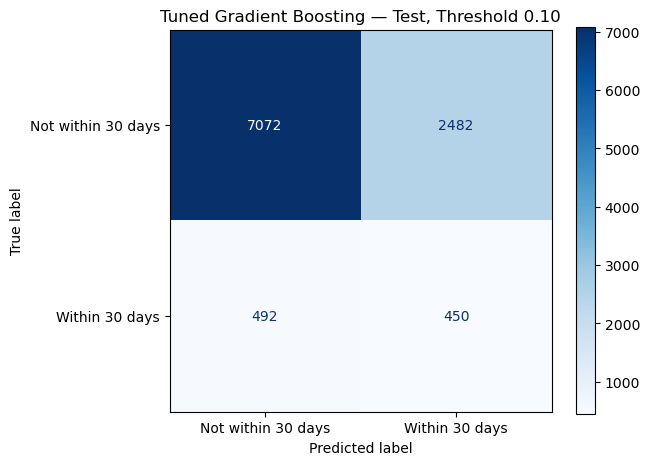

In [70]:
# Show correct predictions, false alerts, and missed readmissions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    display_labels=["Not within 30 days", "Within 30 days"],
    cmap="Blues",
    values_format="d",
)

plt.title("Tuned Gradient Boosting — Test, Threshold 0.10")
plt.tight_layout()
plt.show()


Plot the test confusion matrix. Need to consider false alerts and missed readmissions alongside the correct predictions.

In [71]:
import joblib

# Create folders if they do not exist
Path("models").mkdir(parents=True, exist_ok=True)
Path("reports").mkdir(parents=True, exist_ok=True)

# Save the fitted preprocessing/model pipeline and decision threshold
joblib.dump(
    {
        "pipeline": final_model,
        "threshold": final_threshold,
        "input_columns": X_train.columns.tolist(),
        "tuning_settings": boosting_search.best_params_,
    },
    "models/final_gradient_boosting.joblib",
)

# Save the final test metrics
test_results.to_csv(
    "reports/final_gradient_boosting_test_metrics.csv",
    index=False,
)

print("Model and test results saved.")


Model and test results saved.


Save the final pipeline, threshold, input columns, tuning settings, and test metrics. Calibration, fairness, and performance on new data still need to be evaluated.

In [72]:
from sklearn.metrics import confusion_matrix

# Rows = actual class; columns = predicted class
# Output layout: [[true negatives, false positives],
#                 [false negatives, true positives]]
print(confusion_matrix(y_test, test_prediction, labels=[0, 1]))


[[7072 2482]
 [ 492  450]]


True negatives = 7,072, false positives = 2,482, false negatives = 492, and true positives = 450. The model still misses 492 readmissions at threshold 0.10.

In [73]:
import numpy as np

# Rank patients by predicted risk and select the highest-risk 20%.
# Round upward because we cannot select a fraction of a patient.
n_selected = int(np.ceil(0.20 * len(y_test)))
top_indices = np.argsort(-test_probability, kind="stable")[:n_selected]

total_readmissions = int(y_test.sum())
captured_readmissions = int(y_test.iloc[top_indices].sum())

selected_fraction = n_selected / len(y_test)
capture_rate = captured_readmissions / total_readmissions
precision_at_20 = captured_readmissions / n_selected
lift = capture_rate / selected_fraction

print(f"Patients selected: {n_selected:,} ({selected_fraction:.2%})")
print(f"Readmissions captured: {captured_readmissions:,} "
      f"of {total_readmissions:,}")
print(f"Top-20% capture rate: {capture_rate:.2%}")
print(f"Precision among selected patients: {precision_at_20:.2%}")
print(f"Lift over random selection: {lift:.2f}x")
print(f"30% capture target met: {capture_rate >= 0.30}")


Patients selected: 2,100 (20.01%)
Readmissions captured: 369 of 942
Top-20% capture rate: 39.17%
Precision among selected patients: 17.57%
Lift over random selection: 1.96x
30% capture target met: True


Top 20% selects 2,100 patients and captures 369 of 942 readmissions or 39.17%. Precision = 17.57% and lift = 1.96 times random selection. The 30% capture target is met. This shows prioritization ability, not proof that follow-up prevents readmission.

# Final model audits

Load the saved model and complete the checks suggested in notebook 6. I keep the fitted model and threshold 0.10 unchanged. Use validation data for explanations and calibration diagnostics. Test results are reported for the existing model, not used to select new settings.

The top-20% calculation is already saved above. The following sections also report this policy for validation and test patients. No calibration adjustment or refitting of the saved model is performed. Learning curves fit separate copies on training folds only.

In [74]:
# Load the saved pipeline so these audit cells do not require retraining
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, brier_score_loss, log_loss, confusion_matrix,
)

import sklearn
assert sklearn.__version__ == "1.8.0", "Use the AIM environment with scikit-learn 1.8.0, matching the saved model."
audit_artifact = joblib.load("models/final_gradient_boosting.joblib")
audit_model = audit_artifact["pipeline"]
audit_threshold = float(audit_artifact["threshold"])
audit_columns = audit_artifact["input_columns"]
audit_frames = {
    split: pd.read_csv(f"data/processed/{split}_fe.csv")
    for split in ["train", "val", "test"]
}
audit_X = {split: frame[audit_columns] for split, frame in audit_frames.items()}
audit_y = {split: frame["readmit_30"].to_numpy() for split, frame in audit_frames.items()}
audit_scores = {
    split: audit_model.predict_proba(features)[:, 1]
    for split, features in audit_X.items()
}
assert set(audit_model.classes_) == {0, 1}
assert audit_threshold == 0.10, "Recheck the final threshold and interpretation."
saved_metrics = pd.read_csv("reports/final_gradient_boosting_test_metrics.csv").iloc[0]
assert np.isclose(average_precision_score(audit_y["test"], audit_scores["test"]),
                  saved_metrics["Average precision"])
assert np.isclose(roc_auc_score(audit_y["test"], audit_scores["test"]),
                  saved_metrics["ROC-AUC"])
print("Saved model loaded. Test ranking metrics match the final report.")
print("Decision threshold:", audit_threshold)
print("Predictor columns:", len(audit_columns))


Saved model loaded. Test ranking metrics match the final report.
Decision threshold: 0.1
Predictor columns: 45


Saved model is used for the audit. Matching the saved test report checks that I am evaluating the same model, input columns, and data. This does not establish how often the test set was accessed in earlier experiments.

## Overfitting and policy comparison

In [75]:
# Compare training and held-out performance without refitting
audit_performance = []
audit_policies = []
audit_top_masks = {}
for split in ["train", "val", "test"]:
    labels, scores = audit_y[split], audit_scores[split]
    audit_performance.append({
        "Split": split, "Patients": len(labels), "Positive rate": labels.mean(),
        "AP": average_precision_score(labels, scores),
        "ROC-AUC": roc_auc_score(labels, scores),
    })
    if split == "train":
        continue
    top_mask = np.zeros(len(labels), dtype=bool)
    top_mask[np.argsort(-scores, kind="stable")[:int(np.ceil(0.20 * len(labels)))]] = True
    audit_top_masks[split] = top_mask
    for policy, mask in [("Threshold 0.10", scores >= audit_threshold),
                         ("Top 20%", top_mask)]:
        capture = recall_score(labels, mask, zero_division=0)
        audit_policies.append({
            "Split": split, "Policy": policy, "Selected": int(mask.sum()),
            "Selected fraction": mask.mean(),
            "Captured": int(labels[mask].sum()), "Capture": capture,
            "Precision": precision_score(labels, mask, zero_division=0),
            "Lift": capture / mask.mean(),
        })
audit_performance = pd.DataFrame(audit_performance)
audit_policies = pd.DataFrame(audit_policies)
print(audit_performance.round(4).to_string(index=False))
print("\nPolicy comparison:")
print(audit_policies.round(4).to_string(index=False))


Split  Patients  Positive rate     AP  ROC-AUC
train     48978         0.0897 0.2375   0.7034
  val     10496         0.0897 0.1696   0.6454
 test     10496         0.0897 0.1866   0.6523

Policy comparison:
Split         Policy  Selected  Selected fraction  Captured  Capture  Precision   Lift
  val Threshold 0.10      2976             0.2835       439   0.4660     0.1475 1.6436
  val        Top 20%      2100             0.2001       360   0.3822     0.1714 1.9101
 test Threshold 0.10      2932             0.2793       450   0.4777     0.1535 1.7101
 test        Top 20%      2100             0.2001       369   0.3917     0.1757 1.9579


Training results should be interpreted separately from validation and test results. A training–validation gap suggests some overfitting. Top 20% selects a fixed workload, while threshold 0.10 can flag a different share of patients. Lift compares capture with the expected capture from random selection at the same workload.

## Validation calibration check

                       Model  Brier score  Log loss  Mean predicted risk  Observed positive rate
     Saved gradient boosting      0.07918   0.28917              0.08921                 0.08975
Training-prevalence baseline      0.08169   0.30196              0.08969                 0.08975

Validation risk groups:
                  Patients  Positives  Mean_score  Observed_rate
Bin                                                             
(0.0207, 0.0476]      1050         38      0.0408         0.0362
(0.0476, 0.0552]      1050         66      0.0515         0.0629
(0.0552, 0.0619]      1049         55      0.0586         0.0524
(0.0619, 0.0683]      1050         70      0.0651         0.0667
(0.0683, 0.0755]      1049         80      0.0719         0.0763
(0.0755, 0.0853]      1050         83      0.0802         0.0790
(0.0853, 0.0979]      1049        100      0.0915         0.0953
(0.0979, 0.113]       1050         90      0.1051         0.0857
(0.113, 0.144]        1049        

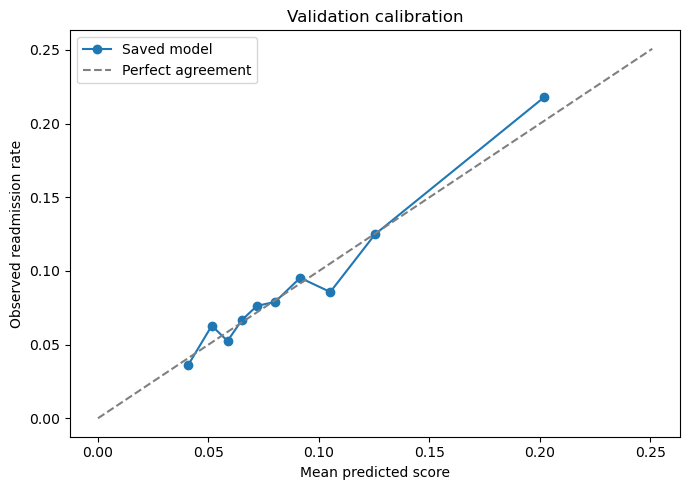

In [76]:
# Check whether validation scores agree with observed readmission rates
from sklearn.calibration import calibration_curve

val_labels, val_scores = audit_y["val"], audit_scores["val"]
baseline_scores = np.full(len(val_labels), audit_y["train"].mean())
calibration_metrics = pd.DataFrame([
    {"Model": name, "Brier score": brier_score_loss(val_labels, scores),
     "Log loss": log_loss(val_labels, scores), "Mean predicted risk": scores.mean(),
     "Observed positive rate": val_labels.mean()}
    for name, scores in [("Saved gradient boosting", val_scores),
                         ("Training-prevalence baseline", baseline_scores)]
])
print(calibration_metrics.round(5).to_string(index=False))
calibration_data = pd.DataFrame({"Score": val_scores, "Readmitted": val_labels})
calibration_data["Bin"] = pd.qcut(calibration_data["Score"], 10, duplicates="drop")
calibration_table = calibration_data.groupby("Bin", observed=True).agg(
    Patients=("Readmitted", "size"), Positives=("Readmitted", "sum"),
    Mean_score=("Score", "mean"), Observed_rate=("Readmitted", "mean"),
)
print("\nValidation risk groups:")
print(calibration_table.round(4).to_string())
observed, predicted = calibration_curve(val_labels, val_scores, n_bins=10, strategy="quantile")
plt.figure(figsize=(7, 5))
plt.plot(predicted, observed, "o-", label="Saved model")
limit = max(predicted.max(), observed.max()) * 1.15
plt.plot([0, limit], [0, limit], "--", color="gray", label="Perfect agreement")
plt.xlabel("Mean predicted score")
plt.ylabel("Observed readmission rate")
plt.title("Validation calibration")
plt.legend()
plt.tight_layout()
plt.show()


Compare predicted scores with observed readmission rates in each group. Lower Brier score and log loss indicate better probabilistic predictions, but neither metric alone proves good calibration. The prevalence baseline gives a useful comparison for this imbalanced dataset. No calibration adjustment is fitted here. 

## Final-model explainability on validation data

                 Feature  Mean AP decrease  Repeat standard deviation
discharge_disposition_id           0.05616                    0.00319
        number_inpatient           0.01861                    0.00176
              payer_code           0.00733                    0.00287
        number_diagnoses           0.00527                    0.00139
             age_numeric           0.00250                    0.00097
        time_in_hospital           0.00192                    0.00134
     admission_source_id           0.00191                    0.00052
            diag_1_group           0.00175                    0.00090
     diabetes_diag_count           0.00171                    0.00066
       prior_utilization           0.00151                    0.00035
       medical_specialty           0.00126                    0.00222
            diag_2_group           0.00096                    0.00068
         num_medications           0.00068                    0.00077
       num_diabetes_

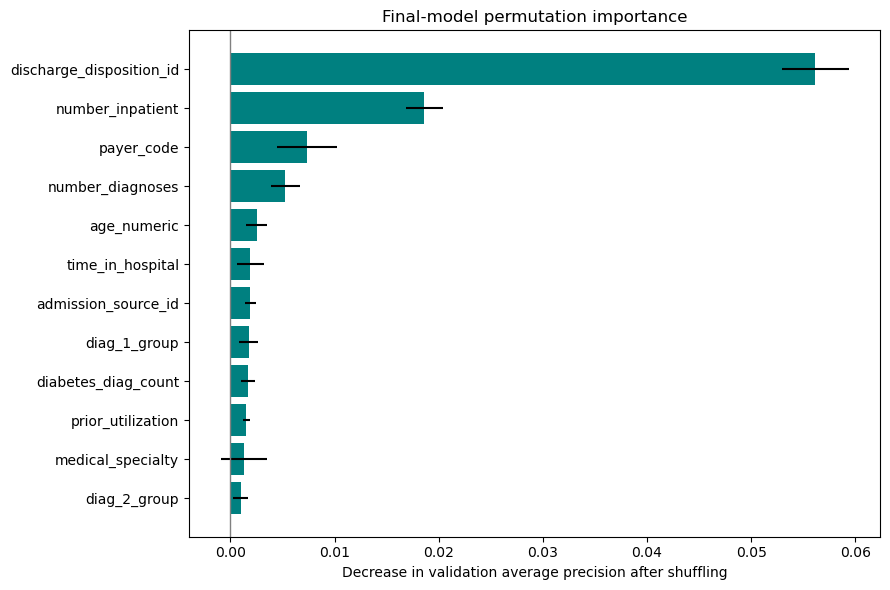

In [77]:
# Shuffle one input column at a time and measure the change in validation AP
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    audit_model, audit_X["val"], audit_y["val"],
    scoring="average_precision", n_repeats=5, random_state=42, n_jobs=1,
)
audit_importance = pd.DataFrame({
    "Feature": audit_columns,
    "Mean AP decrease": importance_result.importances_mean,
    "Repeat standard deviation": importance_result.importances_std,
}).sort_values("Mean AP decrease", ascending=False)
print(audit_importance.head(15).round(5).to_string(index=False))
top_importance = audit_importance.head(12).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top_importance["Feature"], top_importance["Mean AP decrease"],
         xerr=top_importance["Repeat standard deviation"], color="teal")
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Decrease in validation average precision after shuffling")
plt.title("Final-model permutation importance")
plt.tight_layout()
plt.show()


A larger AP decrease means the fitted model relied more on that column in this validation check. Repeat standard deviation shows shuffle variability, not a confidence interval. Correlated features can share information, so an important feature may have a small individual decrease. Shuffling related features separately can also create unusual combinations. These results describe this model, not causes of readmission. I do not use test feature importance to select a new model.

### PDP, ICE and representative prediction sensitivity

Permutation importance identifies predictive reliance but does not show how scores respond to feature values. The following [PDP and ICE analysis](https://scikit-learn.org/1.8/modules/partial_dependence.html) uses the **complete saved pipeline with brute-force probability predictions** on a reproducible background of approximately 1,000 validation patients. Red lines average the model's scenario scores (PDP); thin lines show responses for 60 individual profiles (ICE). These lines are model responses, not observed readmission frequencies or confidence intervals.

Age and hospital-stay grids use observed values; lab-test grids cover the 5th–95th percentiles. Previous inpatient visits cover zero through the 95th percentile, with a support table showing coverage. Because `prior_inpatient` and `prior_utilization` are deterministic functions of inpatient counts, they are updated together when varying `number_inpatient`. That panel is a **coherent joint scenario curve**, rather than a single-column PDP.

Representative true-positive, false-positive, false-negative and true-negative profiles are chosen nearest each outcome group's median validation score. Their ICE curves show individual score sensitivity. They are descriptive examples, not additive feature attributions or causal counterfactuals. Common discharge categories are examined separately with a categorical PDP. Correlated features and medically incompatible combinations can still make scenarios unrealistic; prediction sensitivity does not establish that changing a feature would change a patient's outcome. No model or threshold is chosen using these plots.

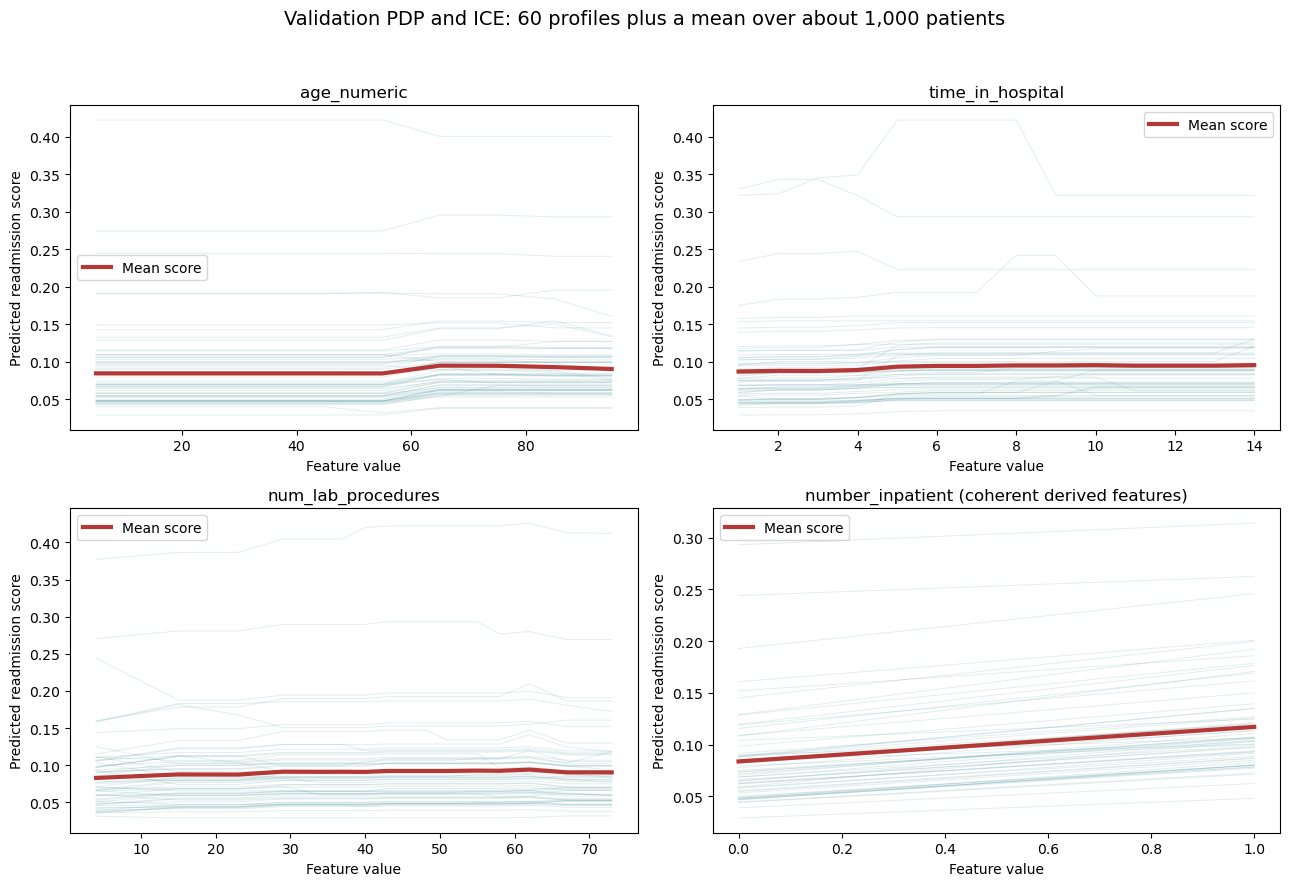

,Feature,Grid low,Grid high,Observed min,Observed max,Validation fraction within grid
0,age_numeric,5.0,95.0,5,95,1.0000
1,time_in_hospital,1.0,14.0,1,14,1.0000
2,num_lab_procedures,4.0,73.0,1,121,0.9033
3,number_inpatient,0.0,1.0,0,9,0.9639


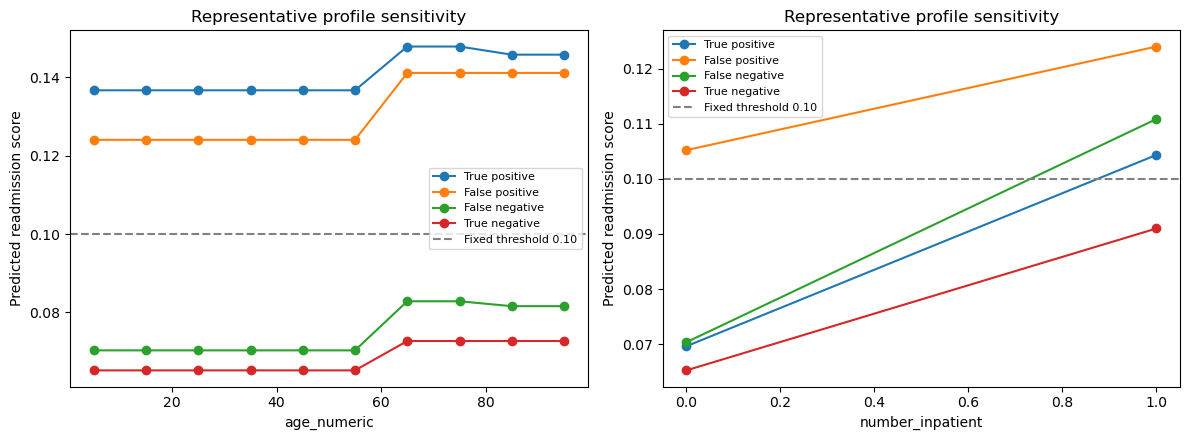

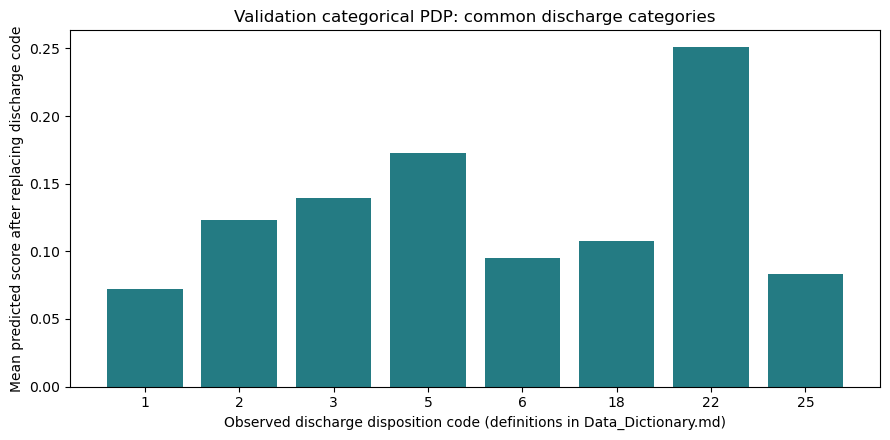

,Discharge code,Mean scenario score,Observed validation patients
0,1,0.0720,6610
1,2,0.1230,230
2,3,0.1397,1318
3,5,0.1725,142
4,6,0.0950,1267
5,18,0.1073,407
6,22,0.2508,194
7,25,0.0833,110


Explanation outputs saved to reports/final_audit/fairness_explainability


In [78]:
fairness_dir = Path("reports/final_audit/fairness_explainability")
fairness_dir.mkdir(parents=True, exist_ok=True)

# Brute-force pipeline PDP/ICE avoids the HistGradientBoosting recursion offset.
# Use a reproducible validation background only; test data are not used here.
explain_rng = np.random.default_rng(20261012)
explain_X = audit_X["val"]
explain_labels = audit_y["val"]
explain_scores = audit_scores["val"]
explain_predicted = explain_scores >= audit_threshold
explain_outcomes = np.select(
    [(explain_labels == 1) & explain_predicted,
     (explain_labels == 0) & explain_predicted,
     (explain_labels == 1) & ~explain_predicted],
    ["True positive", "False positive", "False negative"], default="True negative")

# Pick one actual profile nearest the median score within each error category.
explain_representatives = {}
for outcome in ["True positive", "False positive", "False negative", "True negative"]:
    candidates = np.flatnonzero(explain_outcomes == outcome)
    if len(candidates):
        median = np.median(explain_scores[candidates])
        explain_representatives[outcome] = int(candidates[np.argmin(abs(explain_scores[candidates] - median))])
background_positions = explain_rng.choice(len(explain_X), min(1000, len(explain_X)), replace=False)
background_positions = np.unique(np.r_[background_positions, list(explain_representatives.values())])
background = explain_X.iloc[background_positions].copy()
ice_positions = explain_rng.choice(len(background), min(60, len(background)), replace=False)
representative_offsets = {name: int(np.flatnonzero(background_positions == position)[0])
                          for name, position in explain_representatives.items()}

explain_grids = {
    "age_numeric": np.sort(explain_X.age_numeric.dropna().unique()),
    "time_in_hospital": np.sort(explain_X.time_in_hospital.dropna().unique()),
    "num_lab_procedures": np.unique(np.rint(np.quantile(explain_X.num_lab_procedures.dropna(), np.linspace(.05, .95, 16)))),
    "number_inpatient": np.arange(0, int(np.quantile(explain_X.number_inpatient, .95)) + 1),
}
explain_curves, explain_local_rows, explain_support = [], [], []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for axis, (feature, grid) in zip(axes.flat, explain_grids.items()):
    predictions = []
    for value in grid:
        changed = background.copy()
        changed[feature] = value
        if feature == "number_inpatient":
            # Preserve deterministic feature formulas instead of impossible combinations.
            changed["prior_inpatient"] = int(value > 0)
            changed["prior_utilization"] = changed.number_outpatient + changed.number_emergency + value
        predictions.append(audit_model.predict_proba(changed)[:, 1])
    predictions = np.asarray(predictions)
    average = predictions.mean(axis=1)
    for offset in ice_positions:
        axis.plot(grid, predictions[:, offset], color="#247b83", alpha=.13, linewidth=.7)
    axis.plot(grid, average, color="#b43835", linewidth=3, label="Mean score")
    axis.set_title(feature + (" (coherent derived features)" if feature == "number_inpatient" else ""))
    axis.set_xlabel("Feature value")
    axis.set_ylabel("Predicted readmission score")
    axis.legend(loc="best")
    for value, mean_score in zip(grid, average):
        explain_curves.append({"Feature": feature, "Value": value, "Mean score": mean_score,
                               "Background patients": len(background),
                               "Method": "Coherent joint scenario" if feature == "number_inpatient" else "PDP"})
    explain_support.append({"Feature": feature, "Grid low": min(grid), "Grid high": max(grid),
                            "Observed min": explain_X[feature].min(), "Observed max": explain_X[feature].max(),
                            "Validation fraction within grid": explain_X[feature].between(min(grid), max(grid)).mean()})
    for outcome, offset in representative_offsets.items():
        for value, score in zip(grid, predictions[:, offset]):
            explain_local_rows.append({"Outcome": outcome, "Feature": feature, "Scenario value": value,
                                       "Predicted score": score,
                                       "Actual feature value": float(background.iloc[offset][feature]),
                                       "Original predicted score": explain_scores[explain_representatives[outcome]]})
fig.suptitle("Validation PDP and ICE: 60 profiles plus a mean over about 1,000 patients", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .95))
fig.savefig(fairness_dir / "validation_pdp_ice.png", dpi=160, bbox_inches="tight")
plt.show()
explain_curves = pd.DataFrame(explain_curves)
explain_local = pd.DataFrame(explain_local_rows)
explain_support = pd.DataFrame(explain_support)
explain_curves.to_csv(fairness_dir / "numeric_dependence.csv", index=False)
explain_local.to_csv(fairness_dir / "representative_ice.csv", index=False)
explain_support.to_csv(fairness_dir / "dependence_grid_support.csv", index=False)
display(explain_support.round(4))

# Highlight score sensitivity for representative TP/FP/FN/TN profiles.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, feature in zip(axes, ["age_numeric", "number_inpatient"]):
    for outcome in explain_representatives:
        subset = explain_local[(explain_local.Outcome == outcome) & (explain_local.Feature == feature)]
        axis.plot(subset["Scenario value"], subset["Predicted score"], "o-", label=outcome)
    axis.axhline(audit_threshold, color="gray", linestyle="--", label="Fixed threshold 0.10")
    axis.set_xlabel(feature)
    axis.set_ylabel("Predicted readmission score")
    axis.set_title("Representative profile sensitivity")
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(fairness_dir / "representative_ice.png", dpi=160, bbox_inches="tight")
plt.show()

# Categorical PDP for observed discharge categories with at least 100 validation rows.
discharge_counts = explain_X.discharge_disposition_id.value_counts()
discharge_codes = discharge_counts[discharge_counts >= 100].index.sort_values()
category_rows = []
for code in discharge_codes:
    changed = background.copy()
    changed["discharge_disposition_id"] = code
    category_rows.append({"Discharge code": int(code), "Mean scenario score": audit_model.predict_proba(changed)[:, 1].mean(),
                          "Observed validation patients": int(discharge_counts[code])})
explain_discharge = pd.DataFrame(category_rows)
explain_discharge.to_csv(fairness_dir / "discharge_categorical_pdp.csv", index=False)
fig, axis = plt.subplots(figsize=(9, 4.5))
axis.bar(explain_discharge["Discharge code"].astype(str), explain_discharge["Mean scenario score"], color="#247b83")
axis.set_xlabel("Observed discharge disposition code (definitions in Data_Dictionary.md)")
axis.set_ylabel("Mean predicted score after replacing discharge code")
axis.set_title("Validation categorical PDP: common discharge categories")
fig.tight_layout()
fig.savefig(fairness_dir / "discharge_pdp.png", dpi=160, bbox_inches="tight")
plt.show()
display(explain_discharge.round(4))
print("Explanation outputs saved to", fairness_dir)


### What the executed explanations show

- `age_numeric`: mean scenario score 8.45% at 5, versus 9.04% at 95. This describes the fitted model response over this grid, not a causal effect.
- `time_in_hospital`: mean scenario score 8.68% at 1, versus 9.53% at 14. This describes the fitted model response over this grid, not a causal effect.
- `num_lab_procedures`: mean scenario score 8.29% at 4, versus 9.04% at 73. This describes the fitted model response over this grid, not a causal effect.
- `number_inpatient`: mean scenario score 8.37% at 0, versus 11.71% at 1. This describes the fitted model response over this grid, not a causal effect.

Read the ICE spread alongside the mean: different profiles can respond differently even where the mean appears smooth or nearly flat. The representative-profile curves show that a feature response alone does not explain why a patient was misclassified; outcomes remain uncertain and unmeasured factors may matter. The discharge PDP complements its high permutation importance, but hypothetical transfers between discharge categories can be medically unrealistic. The low precision of the fixed policy remains a practical limitation even if a model response is interpretable. These plots support transparent model inspection, not clinically actionable recommendations.

## Subgroup performance and fairness check

In [79]:
# Apply the same global decision policies to race, gender, and age groups
def wilson_interval(positives, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    rate = positives / total
    denominator = 1 + z*z/total
    center = (rate + z*z/(2*total)) / denominator
    margin = z*np.sqrt(rate*(1-rate)/total + z*z/(4*total*total))/denominator
    return center - margin, center + margin

subgroup_rows = []
for split in ["val", "test"]:
    for attribute in ["race", "gender", "age"]:
        for group, indices in audit_frames[split].groupby(attribute, dropna=False).groups.items():
            positions = np.asarray(list(indices), dtype=int)
            labels, scores = audit_y[split][positions], audit_scores[split][positions]
            positives = int(labels.sum())
            for policy, global_mask in [("Threshold 0.10", audit_scores[split] >= audit_threshold),
                                        ("Top 20%", audit_top_masks[split])]:
                mask = global_mask[positions]
                captured = int(labels[mask].sum())
                low, high = wilson_interval(captured, positives)
                subgroup_rows.append({
                    "Split": split, "Attribute": attribute, "Group": str(group),
                    "Policy": policy, "Patients": len(labels), "Positives": positives,
                    "Selected": int(mask.sum()), "Selection rate": mask.mean(),
                    "Recall": captured/positives if positives else np.nan,
                    "Recall CI low": low, "Recall CI high": high,
                    "Precision": captured/int(mask.sum()) if mask.sum() else np.nan,
                    "AP": average_precision_score(labels, scores) if positives else np.nan,
                    "ROC-AUC": roc_auc_score(labels, scores) if len(np.unique(labels)) == 2 else np.nan,
                    "Brier": brier_score_loss(labels, scores),
                    "Mean score": scores.mean(), "Observed rate": labels.mean(),
                    "Small positive count": positives < 30,
                })
audit_subgroups = pd.DataFrame(subgroup_rows)
print(audit_subgroups.round(4).to_string(index=False))


Split Attribute           Group         Policy  Patients  Positives  Selected  Selection rate  Recall  Recall CI low  Recall CI high  Precision     AP  ROC-AUC  Brier  Mean score  Observed rate  Small positive count
  val      race AfricanAmerican Threshold 0.10      1806        159       414          0.2292  0.4465         0.3714          0.5242     0.1715 0.1739   0.6527 0.0777      0.0841         0.0880                 False
  val      race AfricanAmerican        Top 20%      1806        159       300          0.1661  0.3711         0.2998          0.4484     0.1967 0.1739   0.6527 0.0777      0.0841         0.0880                 False
  val      race           Asian Threshold 0.10        84          6        20          0.2381  0.5000         0.1876          0.8124     0.1500 0.2942   0.6645 0.0624      0.0804         0.0714                  True
  val      race           Asian        Top 20%        84          6        11          0.1310  0.3333         0.0968          0.7000    

Compare recall, precision, and calibration indicators alongside group sizes. Recall intervals help show uncertainty, especially when a group has few readmissions. Groups with fewer than 30 positives are flagged for cautious interpretation. Undefined metrics are shown as missing rather than as zero. Top 20% uses the overall ranking, not a separate quota within each group. These comparisons can identify gaps, but do not prove fairness or establish discrimination. No subgroup-specific threshold is chosen from test results.

### Explicit fairness metrics, uncertainty and intersectional checks

Evaluate both **unchanged global policies** on validation and test data. Here selection means access to potential additional follow-up, so both missed readmissions and unnecessary workload matter. Metrics use [Fairlearn's max/min definitions](https://fairlearn.org/main/user_guide/assessment/perform_fairness_assessment.html), calculated directly from confusion counts without an additional dependency:

| Measure | Definition | Interpretation |
|---|---|---|
| Demographic parity difference | Maximum minus minimum group selection rate | Access to follow-up differs across groups |
| Selection-rate min/max ratio | Minimum divided by maximum selection rate | Relative access disparity; one denotes parity |
| Equal opportunity difference | Maximum minus minimum true-positive rate (TPR/recall) | Coverage of recorded readmissions differs |
| FPR difference | Maximum minus minimum false-positive rate | Follow-up workload among recorded negatives differs |
| Equalized odds difference | Larger of the TPR and FPR differences | Summarizes both types of error disparity |

Race, gender and age are audited separately and race × gender intersections are added. Payer code is an **exploratory insurance/access proxy**; it does not measure income or socioeconomic status. Missing categories remain labelled Unknown. Every group is retained in the exported results. Summaries show both all groups and a separately labelled subset with at least 100 patients, 30 positives and 30 negatives. These thresholds flag unstable estimates; they do not guarantee reliability or make excluded groups unimportant.

Per-group selection, TPR and FPR have individual Wilson 95% intervals. Two clearly labelled reference contrasts (AfricanAmerican minus Caucasian; Male minus Female) have 2,000 independent within-group patient-bootstrap intervals. Resampling four confusion cells is equivalent to resampling patients for these fixed-policy rate statistics. These are **descriptive, unadjusted intervals**, not a family of significance tests or a fairness certification. The reference choices are for reporting, not a normative standard. Unequal prevalence, label capture and group composition affect these measures, and parity metrics can conflict. No universal ratio cutoff is used as proof of fairness or discrimination. Test outputs are fixed-model diagnostics, not mitigation-tuning data.

In [80]:
# Explicit fairness metrics for the two fixed global policies.
# Payer is an exploratory insurance/access proxy, not measured socioeconomic status.
from IPython.display import display

fairness_dir = Path("reports/final_audit/fairness_explainability")
fairness_dir.mkdir(parents=True, exist_ok=True)

def fairness_rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan

def fairness_wilson(successes, total):
    if not total:
        return np.nan, np.nan
    z = 1.959963984540054
    rate = successes / total
    divisor = 1 + z ** 2 / total
    center = (rate + z ** 2 / (2 * total)) / divisor
    margin = z * np.sqrt(rate * (1 - rate) / total + z ** 2 / (4 * total ** 2)) / divisor
    return center - margin, center + margin

fairness_group_rows = []
for split in ["val", "test"]:
    frame = audit_frames[split].copy()
    frame["race × gender"] = frame["race"].fillna("Unknown").astype(str) + " × " + frame["gender"].fillna("Unknown").astype(str)
    policies = {"Threshold 0.10": audit_scores[split] >= audit_threshold,
                "Top 20%": audit_top_masks[split]}
    for attribute in ["race", "gender", "age", "payer_code", "race × gender"]:
        group_labels = frame[attribute].fillna("Unknown").astype(str)
        for group in sorted(group_labels.unique()):
            positions = np.flatnonzero(group_labels.to_numpy() == group)
            actual = audit_y[split][positions].astype(bool)
            for policy, global_mask in policies.items():
                predicted = global_mask[positions]
                tn = int((~actual & ~predicted).sum())
                fp = int((~actual & predicted).sum())
                fn = int((actual & ~predicted).sum())
                tp = int((actual & predicted).sum())
                total, positive, negative = len(positions), tp + fn, tn + fp
                row = {"Split": split, "Policy": policy, "Attribute": attribute, "Group": group,
                       "Patients": total, "Positives": positive, "Negatives": negative,
                       "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                       "Prevalence": fairness_rate(positive, total),
                       "Precision": fairness_rate(tp, tp + fp),
                       "Brier": brier_score_loss(actual, audit_scores[split][positions]),
                       "Calibration mean gap": audit_scores[split][positions].mean() - actual.mean(),
                       "Limited support": total < 100 or positive < 30 or negative < 30}
                for metric, successes, denominator in [("Selection rate", tp + fp, total),
                                                         ("TPR", tp, positive), ("FPR", fp, negative)]:
                    row[metric] = fairness_rate(successes, denominator)
                    row[metric + " CI low"], row[metric + " CI high"] = fairness_wilson(successes, denominator)
                fairness_group_rows.append(row)
fairness_groups = pd.DataFrame(fairness_group_rows)

# Max/min metrics across groups: zero difference or ratio one indicates parity on that measure.
# Show all groups AND a separately labelled subset with sufficient descriptive support.
fairness_summary_rows = []
for (split, policy, attribute), groups in fairness_groups.groupby(["Split", "Policy", "Attribute"]):
    for scope in ["All groups", "Supported groups only"]:
        subset = groups if scope == "All groups" else groups[~groups["Limited support"]]
        if len(subset) < 2:
            continue
        tpr_gap = subset.TPR.max() - subset.TPR.min()
        fpr_gap = subset.FPR.max() - subset.FPR.min()
        fairness_summary_rows.append({
            "Split": split, "Policy": policy, "Attribute": attribute, "Scope": scope,
            "Groups": len(subset), "Limited-support groups": int(subset["Limited support"].sum()),
            "Demographic parity difference": subset["Selection rate"].max() - subset["Selection rate"].min(),
            "Selection-rate min/max ratio": fairness_rate(subset["Selection rate"].min(), subset["Selection rate"].max()),
            "Equal opportunity difference": tpr_gap,
            "FPR difference": fpr_gap,
            "Equalized odds difference": max(tpr_gap, fpr_gap),
            "Lowest-selection group": subset.loc[subset["Selection rate"].idxmin(), "Group"],
            "Highest-selection group": subset.loc[subset["Selection rate"].idxmax(), "Group"],
        })
fairness_summary = pd.DataFrame(fairness_summary_rows)
fairness_groups.to_csv(fairness_dir / "group_confusion_rates.csv", index=False)
fairness_summary.to_csv(fairness_dir / "parity_summary.csv", index=False)
display(fairness_summary[(fairness_summary.Scope == "Supported groups only") &
                         fairness_summary.Attribute.isin(["race", "gender", "age"])].round(4))
print("Full group counts, intervals, payer and intersectional results are saved in", fairness_dir)


,Split,Policy,Attribute,Scope,Groups,Limited-support groups,Demographic parity difference,Selection-rate min/max ratio,Equal opportunity difference,FPR difference,Equalized odds difference,Lowest-selection group,Highest-selection group
1,test,Threshold 0.10,age,Supported groups only,6,0,0.3524,0.2156,0.4804,0.3367,0.4804,[30-40),[80-90)
3,test,Threshold 0.10,gender,Supported groups only,2,0,0.0248,0.9149,0.0623,0.0208,0.0623,Male,Female
7,test,Threshold 0.10,race,Supported groups only,2,0,0.0669,0.7764,0.1395,0.0584,0.1395,AfricanAmerican,Caucasian
11,test,Top 20%,age,Supported groups only,6,0,0.2569,0.2261,0.3734,0.2438,0.3734,[30-40),[80-90)
13,test,Top 20%,gender,Supported groups only,2,0,0.0225,0.8930,0.0619,0.0184,0.0619,Male,Female
17,test,Top 20%,race,Supported groups only,2,0,0.0479,0.7765,0.1421,0.0374,0.1421,AfricanAmerican,Caucasian
21,val,Threshold 0.10,age,Supported groups only,6,0,0.3102,0.2940,0.3761,0.2992,0.3761,[30-40),[80-90)
23,val,Threshold 0.10,gender,Supported groups only,2,0,0.0184,0.9370,0.0260,0.0165,0.0260,Male,Female
27,val,Threshold 0.10,race,Supported groups only,2,0,0.0728,0.7590,0.0182,0.0774,0.0774,AfricanAmerican,Caucasian
31,val,Top 20%,age,Supported groups only,6,0,0.2036,0.3251,0.2984,0.1901,0.2984,[30-40),[80-90)


Full group counts, intervals, payer and intersectional results are saved in reports/final_audit/fairness_explainability


,Split,Policy,Attribute,Group A,Reference,Metric,Group A rate,Reference rate,Difference A minus reference,95% lower,95% upper,Selection ratio A/reference
0,val,Threshold 0.10,race,AfricanAmerican,Caucasian,Selection rate,0.2292,0.3020,-0.0728,-0.0930,-0.0509,0.7590
1,val,Threshold 0.10,race,AfricanAmerican,Caucasian,TPR,0.4465,0.4647,-0.0182,-0.0999,0.0687,NaN
2,val,Threshold 0.10,race,AfricanAmerican,Caucasian,FPR,0.2083,0.2856,-0.0774,-0.0985,-0.0553,NaN
3,val,Threshold 0.10,gender,Male,Female,Selection rate,0.2737,0.2921,-0.0184,-0.0360,-0.0008,0.9370
4,val,Threshold 0.10,gender,Male,Female,TPR,0.4518,0.4778,-0.0260,-0.0890,0.0399,NaN
5,val,Threshold 0.10,gender,Male,Female,FPR,0.2568,0.2732,-0.0165,-0.0349,0.0012,NaN
6,val,Top 20%,race,AfricanAmerican,Caucasian,Selection rate,0.1661,0.2116,-0.0455,-0.0652,-0.0258,0.7849
7,val,Top 20%,race,AfricanAmerican,Caucasian,TPR,0.3711,0.3790,-0.0079,-0.0888,0.0758,NaN
8,val,Top 20%,race,AfricanAmerican,Caucasian,FPR,0.1463,0.1948,-0.0485,-0.0678,-0.0299,NaN
9,val,Top 20%,gender,Male,Female,Selection rate,0.1960,0.2036,-0.0076,-0.0235,0.0073,0.9628


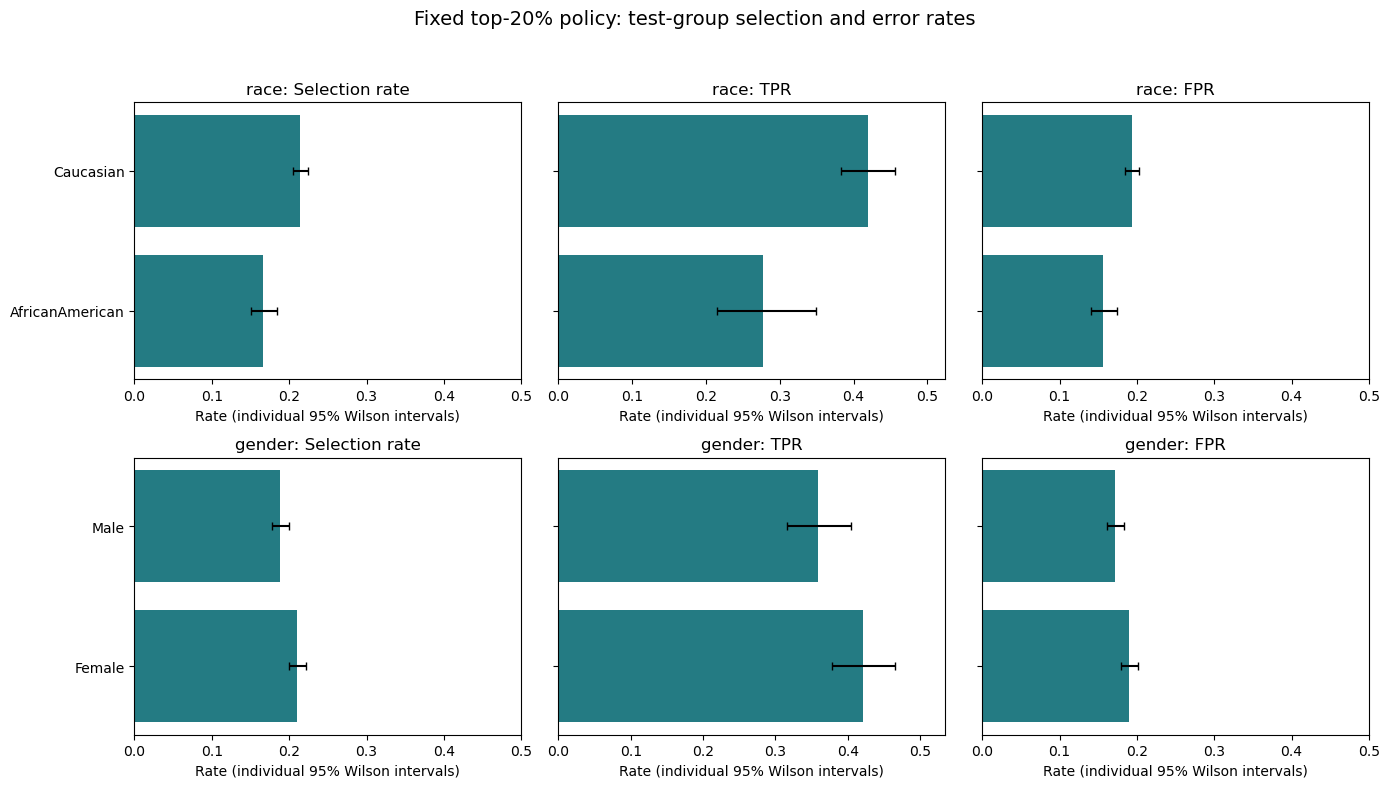

In [81]:
# Descriptive reference-group contrasts, fixed in advance for interpretability.
# Within each group, multinomial resampling of TN/FP/FN/TP is equivalent to a
# patient bootstrap for these fixed-model confusion-count statistics.
fairness_rng = np.random.default_rng(20261012)
fairness_bootstrap_repeats = 2000
fairness_contrast_rows = []
for split in ["val", "test"]:
    for policy in ["Threshold 0.10", "Top 20%"]:
        for attribute, group_a, reference in [("race", "AfricanAmerican", "Caucasian"),
                                               ("gender", "Male", "Female")]:
            selected = fairness_groups[(fairness_groups.Split == split) &
                                      (fairness_groups.Policy == policy) &
                                      (fairness_groups.Attribute == attribute)].set_index("Group")
            a, ref = selected.loc[group_a], selected.loc[reference]
            counts_a = a[["TN", "FP", "FN", "TP"]].to_numpy(dtype=int)
            counts_ref = ref[["TN", "FP", "FN", "TP"]].to_numpy(dtype=int)
            resampled_a = fairness_rng.multinomial(int(a.Patients), counts_a / a.Patients,
                                                  size=fairness_bootstrap_repeats)
            resampled_ref = fairness_rng.multinomial(int(ref.Patients), counts_ref / ref.Patients,
                                                    size=fairness_bootstrap_repeats)
            def resampled_rates(counts):
                tn, fp, fn, tp = counts.T
                def divide(num, den):
                    return np.divide(num, den, out=np.full(len(num), np.nan), where=den > 0)
                return {"Selection rate": divide(tp + fp, counts.sum(axis=1)),
                        "TPR": divide(tp, tp + fn), "FPR": divide(fp, fp + tn)}
            samples_a, samples_ref = resampled_rates(resampled_a), resampled_rates(resampled_ref)
            for metric in ["Selection rate", "TPR", "FPR"]:
                differences = samples_a[metric] - samples_ref[metric]
                lo, hi = np.nanquantile(differences, [.025, .975])
                fairness_contrast_rows.append({
                    "Split": split, "Policy": policy, "Attribute": attribute,
                    "Group A": group_a, "Reference": reference, "Metric": metric,
                    "Group A rate": a[metric], "Reference rate": ref[metric],
                    "Difference A minus reference": a[metric] - ref[metric],
                    "95% lower": lo, "95% upper": hi,
                    "Selection ratio A/reference": fairness_rate(a[metric], ref[metric]) if metric == "Selection rate" else np.nan,
                })
fairness_contrasts = pd.DataFrame(fairness_contrast_rows)
fairness_contrasts.to_csv(fairness_dir / "reference_contrasts.csv", index=False)
display(fairness_contrasts.round(4))

# Plot supported race and gender groups; all groups remain in the saved tables.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey="row")
for row_index, attribute in enumerate(["race", "gender"]):
    subset = fairness_groups[(fairness_groups.Split == "test") &
                             (fairness_groups.Policy == "Top 20%") &
                             (fairness_groups.Attribute == attribute) &
                             ~fairness_groups["Limited support"]].sort_values("Group")
    for column_index, metric in enumerate(["Selection rate", "TPR", "FPR"]):
        axis = axes[row_index, column_index]
        rates = subset[metric].to_numpy()
        errors = np.vstack([rates - subset[metric + " CI low"], subset[metric + " CI high"] - rates])
        axis.barh(subset.Group, rates, xerr=errors, color="#247b83", capsize=3)
        axis.set_xlim(0, max(.5, subset[metric + " CI high"].max() * 1.15))
        axis.set_title(attribute + ": " + metric)
        axis.set_xlabel("Rate (individual 95% Wilson intervals)")
fig.suptitle("Fixed top-20% policy: test-group selection and error rates", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .95))
fig.savefig(fairness_dir / "fairness_rates.png", dpi=160, bbox_inches="tight")
plt.show()


### Fairness findings and feasible mitigation plan

- **AfricanAmerican versus Caucasian, test top-20% policy:** TPR 27.71% versus 41.92%; difference -14.21 percentage points (individual bootstrap 95% interval -21.90 to -6.06). Selection rates are 16.66% versus 21.45% (A/reference ratio 0.777); FPRs are 15.63% versus 19.37%.
- **Male versus Female, test top-20% policy:** TPR 35.89% versus 42.08%; difference -6.19 percentage points (individual bootstrap 95% interval -12.37 to +0.24). Selection rates are 18.82% versus 21.07% (A/reference ratio 0.893); FPRs are 17.15% versus 18.99%.

These observed coverage and workload disparities warrant investigation. They do not identify causes or establish discrimination. All-group max/min gaps can be driven by very small groups; use the support flags and intervals rather than ranking fairness by a single summary number. Age-related differences can reflect clinical risk and differences in captured outcomes. Insurance and intersectional findings are exploratory and require contextual interpretation. The two operating policies have different workloads, so their parity differences should not be treated as a controlled model comparison.

**Practical priority:** investigate lower coverage of recorded readmissions, while monitoring false-positive workload, overall capture and calibration. Agree with care-management stakeholders on acceptable coverage gaps and follow-up capacity before setting mitigation objectives. The following actions are proposals; no mitigation is claimed to have succeeded:

| Evidence or concern | Proposed action | How to evaluate it |
|---|---|---|
| Race/gender TPR gaps | Investigate outcome completeness, care access, discharge coding and group calibration; consult affected stakeholders | Compare label capture and calibration with group counts and uncertainty |
| Sparse race, age or intersectional strata | Improve representative data and outcome linkage; use grouped training folds where feasible | Report group support and independent cohort intervals; do not silently remove groups |
| Potential reliance on protected attributes and access proxies | Compare models with/without race, gender and payer; examine correlated proxies | Refit candidates on training data, compare validation AP, capture, TPR/FPR gaps and calibration; attribute removal alone does not guarantee fairness |
| Coverage differences persist after data checks | Evaluate group/outcome reweighting during training | Choose weights with training CV; assess validation utility and disparities under the same capacity constraint |
| Threshold or calibration mismatch | Evaluate calibrated scores and a capacity-constrained policy; consider group-aware post-processing only after stakeholder review | Fit calibration/post-processing within training folds; evaluate validation metrics and tradeoffs, then lock the policy |
| Risk of optimistic mitigation claims | Obtain recent independent data for the final mitigated candidate | Existing test results have already been examined; an untouched external cohort is needed for clean confirmation |

Do not optimize group thresholds from these test outcomes, mechanically enforce equal rates despite clinical context, or interpret the audit as deployment approval. Record the chosen tradeoff and uncertainty explicitly. All new CSV tables and PNG figures are saved under `reports/final_audit/fairness_explainability/`.

## Error analysis and representative predictions

In [82]:
# Summarize errors and inspect examples using validation patients
validation_predictions = val_scores >= audit_threshold
validation_errors = audit_frames["val"].copy()
validation_errors["Predicted_score"] = val_scores
validation_errors["Flagged"] = validation_predictions
validation_errors["Outcome"] = np.select(
    [(val_labels == 1) & validation_predictions,
     (val_labels == 0) & validation_predictions,
     (val_labels == 1) & ~validation_predictions],
    ["True positive", "False positive", "False negative"], default="True negative",
)
error_features = ["age_numeric", "time_in_hospital", "prior_utilization",
                  "number_inpatient", "num_diabetes_meds", "Predicted_score"]
print("Validation error-group counts:")
print(validation_errors["Outcome"].value_counts().to_string())
print("\nMedian feature values by validation error group:")
print(validation_errors.groupby("Outcome")[error_features].median().round(3).to_string())
example_positions = []
for outcome in ["True positive", "False positive", "False negative", "True negative"]:
    candidates = validation_errors[validation_errors["Outcome"] == outcome]
    if len(candidates):
        median_score = candidates["Predicted_score"].median()
        example_positions.append((candidates["Predicted_score"]-median_score).abs().idxmin())
example_columns = ["Outcome", "readmit_30", "Predicted_score", "age",
                   "prior_utilization", "time_in_hospital", "discharge_disposition_id"]
print("\nValidation examples nearest each error group's median score:")
print(validation_errors.loc[example_positions, example_columns].round(4).to_string(index=False))
for policy, mask in [("Threshold 0.10", audit_scores["test"] >= audit_threshold),
                     ("Top 20%", audit_top_masks["test"])]:
    print("\nTest confusion matrix:", policy)
    print(confusion_matrix(audit_y["test"], mask, labels=[0, 1]))


Validation error-group counts:
Outcome
True negative     7017
False positive    2537
False negative     503
True positive      439

Median feature values by validation error group:
                age_numeric  time_in_hospital  prior_utilization  number_inpatient  num_diabetes_meds  Predicted_score
Outcome                                                                                                               
False negative         65.0               3.0                0.0               0.0                1.0            0.070
False positive         75.0               5.0                0.0               0.0                1.0            0.124
True negative          65.0               3.0                0.0               0.0                1.0            0.065
True positive          75.0               5.0                1.0               0.0                1.0            0.148

Validation examples nearest each error group's median score:
       Outcome  readmit_30  Predicted_score

False negatives are readmissions missed by the policy. False positives increase follow-up workload among patients without a recorded readmission. The example rows show typical scores within each validation outcome group. Feature values provide context, but do not explain an individual prediction causally. Small differences between error-group medians should not be treated as proven explanations.

## Uncertainty in final test performance

In [83]:
# Bootstrap the test rows with replacement, keeping the fitted model unchanged
# The top-20% ranking is recalculated within each bootstrap sample
audit_rng = np.random.default_rng(42)
bootstrap_rows = []
test_labels, test_scores = audit_y["test"], audit_scores["test"]
for repeat in range(300):
    indices = audit_rng.integers(0, len(test_labels), len(test_labels))
    labels, scores = test_labels[indices], test_scores[indices]
    if len(np.unique(labels)) < 2:
        continue
    prediction = scores >= audit_threshold
    selected = np.argsort(-scores, kind="stable")[:int(np.ceil(0.20*len(labels)))]
    capture = labels[selected].sum() / labels.sum()
    bootstrap_rows.append({
        "AP": average_precision_score(labels, scores),
        "ROC-AUC": roc_auc_score(labels, scores),
        "Threshold precision": precision_score(labels, prediction, zero_division=0),
        "Threshold recall": recall_score(labels, prediction, zero_division=0),
        "Top-20% capture": capture,
        "Top-20% precision": labels[selected].mean(),
        "Top-20% lift": capture/(len(selected)/len(labels)),
    })
bootstrap_table = pd.DataFrame(bootstrap_rows)
point_top = audit_top_masks["test"]
point_prediction = test_scores >= audit_threshold
point_estimates = {
    "AP": average_precision_score(test_labels, test_scores),
    "ROC-AUC": roc_auc_score(test_labels, test_scores),
    "Threshold precision": precision_score(test_labels, point_prediction),
    "Threshold recall": recall_score(test_labels, point_prediction),
    "Top-20% capture": test_labels[point_top].sum()/test_labels.sum(),
    "Top-20% precision": test_labels[point_top].mean(),
    "Top-20% lift": (test_labels[point_top].sum()/test_labels.sum())/point_top.mean(),
}
audit_intervals = pd.DataFrame({
    "Estimate": pd.Series(point_estimates),
    "95% lower": bootstrap_table.quantile(0.025),
    "95% upper": bootstrap_table.quantile(0.975),
})
print(audit_intervals.round(4).to_string())


                     Estimate  95% lower  95% upper
AP                     0.1866     0.1653     0.2079
ROC-AUC                0.6523     0.6317     0.6710
Threshold precision    0.1535     0.1400     0.1651
Threshold recall       0.4777     0.4430     0.5103
Top-20% capture        0.3917     0.3593     0.4160
Top-20% precision      0.1757     0.1576     0.1898
Top-20% lift           1.9579     1.7959     2.0791


The percentile intervals show variation from resampling this test dataset. The 300 repeats provide an approximate uncertainty check. They condition on the existing fitted model and do not include model-training uncertainty, hospital clustering, or differences in future populations. These final-model test intervals do not compare candidate models. The paired validation significance tests above address candidate differences separately.

## Data leakage and identity checks

In [84]:
# Verify exact patient separation using the split manifest and source identifiers.
from itertools import combinations
forbidden = {"readmit_30", "readmitted", "patient_nbr", "encounter_id"}
assert not forbidden.intersection(audit_columns)
manifest = pd.read_csv("data/processed/split_patient_manifest.csv")
identity_source = pd.read_csv("data/processed/diabetic_clean.csv", keep_default_na=False)
identity_source = identity_source[identity_source.gender != "Unknown/Invalid"].copy()
assert identity_source.patient_nbr.is_unique
assert manifest.patient_nbr.is_unique
assert manifest.encounter_id.is_unique
assert len(manifest) == sum(len(frame) for frame in audit_frames.values())
identity_checks = []
split_patient_ids = {}
for split, frame in audit_frames.items():
    rows = manifest[manifest.Split == split].sort_values("Row")
    assert rows.Row.tolist() == list(range(len(frame)))
    original = rows.merge(identity_source, on=["patient_nbr", "encounter_id"],
                          how="left", validate="one_to_one", indicator=True)
    assert original["_merge"].eq("both").all()
    assert ((original.readmitted == "<30").astype(int).to_numpy() == frame.readmit_30.to_numpy()).all()
    # Validate row alignment using every unchanged source predictor.
    common = [column for column in frame.columns if column in identity_source.columns
              and column not in ["A1Cresult", "max_glu_serum"]]
    for column in common:
        expected = original[column].astype(str).replace("", "Unknown").reset_index(drop=True)
        actual = frame[column].astype(str).reset_index(drop=True)
        assert expected.equals(actual), (split, column)
    assert audit_X[split].columns.tolist() == audit_columns
    assert not frame.readmit_30.isna().any()
    split_patient_ids[split] = set(rows.patient_nbr)
    identity_checks.append({"Split": split, "Matched patients": len(rows),
                            "Ambiguous rows": 0, "Unmatched rows": 0})
for first, second in combinations(split_patient_ids, 2):
    assert not split_patient_ids[first].intersection(split_patient_ids[second])
print(pd.DataFrame(identity_checks).to_string(index=False))
print("Exact manifest: no patient overlap; identifiers and target excluded from predictors.")


Split  Matched patients  Ambiguous rows  Unmatched rows
train             48978               0               0
  val             10496               0               0
 test             10496               0               0
Exact manifest: no patient overlap; identifiers and target excluded from predictors.


The separate split manifest retains exact patient and encounter IDs in saved split row order. The audit checks unique identities, source-row alignment and zero patient overlap across all splits. Identifiers are excluded from model predictors. Medication exclusions are learned from training patients only and applied unchanged to validation/test. The code cannot establish every historical test access; prediction time remains discharge.


## Validation learning curves

Fit fresh copies of the same pipeline on increasing portions of the training data. These experiments do not replace the saved final model and do not use the final test set.

 Training rows per fold  Mean training AP  Mean CV AP  CV AP standard deviation
                   8163            0.2445      0.1542                    0.0065
                  16326            0.2294      0.1652                    0.0012
                  32652            0.2318      0.1792                    0.0068


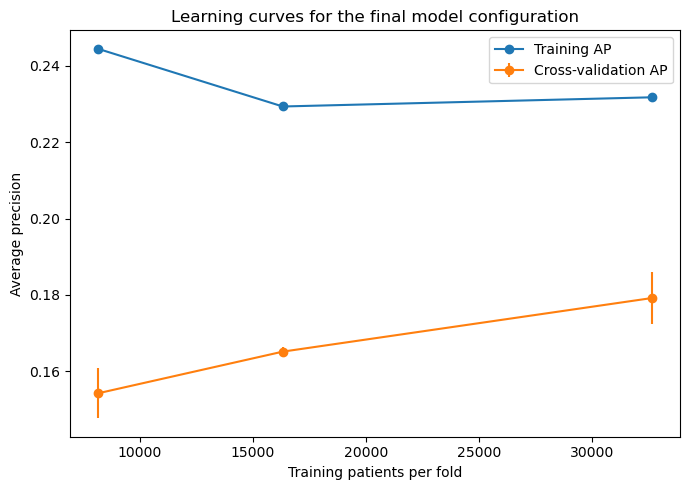

In [85]:
# Check training and cross-validation AP as training size increases
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.base import clone

curve_sizes, curve_train, curve_cv = learning_curve(
    clone(audit_model), audit_X["train"], audit_y["train"],
    train_sizes=[0.25, 0.50, 1.0],
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="average_precision", n_jobs=1, shuffle=True, random_state=42,
    error_score="raise",
)
audit_learning_curve = pd.DataFrame({
    "Training rows per fold": curve_sizes,
    "Mean training AP": curve_train.mean(axis=1),
    "Mean CV AP": curve_cv.mean(axis=1),
    "CV AP standard deviation": curve_cv.std(axis=1),
})
print(audit_learning_curve.round(4).to_string(index=False))
plt.figure(figsize=(7, 5))
plt.plot(curve_sizes, curve_train.mean(axis=1), "o-", label="Training AP")
plt.errorbar(curve_sizes, curve_cv.mean(axis=1), yerr=curve_cv.std(axis=1),
             fmt="o-", label="Cross-validation AP")
plt.xlabel("Training patients per fold")
plt.ylabel("Average precision")
plt.title("Learning curves for the final model configuration")
plt.legend()
plt.tight_layout()
plt.show()


Compare the training and cross-validation curves. A persistent gap suggests overfitting. Increasing CV AP with more data suggests that additional training data may help. These folds reuse training data previously used for tuning, so this is a diagnostic, not an independent model-selection result. Error bars show fold variation, not a 95% confidence interval.

## Save completed audit reports

In [86]:
# Save the completed audit tables without changing the model artifact
audit_report_dir = Path("reports/final_audit")
audit_report_dir.mkdir(parents=True, exist_ok=True)
audit_exports = {
    "split_performance": audit_performance,
    "policy_comparison": audit_policies,
    "validation_calibration_metrics": calibration_metrics,
    "validation_calibration_bins": calibration_table.reset_index(),
    "validation_permutation_importance": audit_importance,
    "subgroup_performance": audit_subgroups,
    "test_bootstrap_intervals": audit_intervals.reset_index(names="Metric"),
    "patient_identity_checks": pd.DataFrame(identity_checks),
    "training_learning_curve": audit_learning_curve,
}
for name, table in audit_exports.items():
    table.to_csv(audit_report_dir / f"{name}.csv", index=False)
print("Saved", len(audit_exports), "audit tables to", audit_report_dir)
import sys, sklearn
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)


Saved 9 audit tables to reports/final_audit
Python: 3.13.12
pandas: 3.0.2 NumPy: 2.4.4 scikit-learn: 1.8.0


## Key findings from the completed audits

Final-model permutation importance ranks discharge_disposition_id, number_inpatient, payer_code highest in this validation check. These rankings describe the fitted model and are affected by correlated features.

Validation Brier score = 0.07918, compared with 0.08169 for the training-prevalence baseline. Inspect the risk-group table and calibration plot as well. The scores were not recalibrated.

Test top-20% capture = 39.17%. Approximate bootstrap 95% interval = 35.93% to 41.60%. The point estimate meets the predefined 30% target. This interval conditions on the saved model and this test population.

Subgroup tables report race, gender, and age performance under both global policies. Small-positive groups are flagged, and recall intervals show uncertainty. Test top-20% recall is 27.71% for AfricanAmerican patients and 41.92% for Caucasian patients. Female recall is 42.08%, compared with 35.89% for Male patients. These observed gaps need investigation alongside sample sizes and intervals. No significance test or fairness certification is implied.

The saved test metrics match the original report. No model artifact or operating threshold was changed. Temporal validation, new-hospital validation, and intervention benefit remain untested.

Learning-curve CV AP increases from 0.1542 at 8,163 training rows per fold to 0.1792 at 32,652. More data may help, but training AP remains higher than CV AP, so the overfitting gap is still present.
